# ***Proyecto de Machine Learning (*MachineCritic*)***

***Realizado por:***

- *Andrés Felipe Mantilla Almeyda 2250931*
- *Manuel Alejandro Rojas Sierra 2250938*

# **Librerías usadas:** 📚

In [ ]:
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ***Exploratory Data Analysis (EDA)*** 📈✅

# **1. Conociendo nuestro DataFrame:**
### 1.1. Leer el DataFrame.
### 1.2. Características del DataFrame.
### 1.3. Limpiar el DataFrame


## *1.1 Leer el DataFrame*

In [ ]:
pdgames = pd.read_parquet("hf://datasets/FronkonGames/steam-games-dataset/data/train-00000-of-00001.parquet") #cargar el dataset
pdgames.head(1).T #primer registro del dataset

,0
appID,2539430
name,Black Dragon Mage Playtest
release_date,"Aug 1, 2023"
estimated_owners,0 - 0
peak_ccu,0
required_age,0
price,0.0
dlc_count,0
detailed_description,
short_description,


## *1.2. Características del dataset*

In [ ]:
print("=="*50 )
print("\t\t\t\tCARACTERÍSTICAS DEL DATASET: ")
print("=="*50 )
print("\n")
print(pdgames.info()) #tabla con cantidad de valores nulos y el tipo
print("\n")

				CARACTERÍSTICAS DEL DATASET: 


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124146 entries, 0 to 124145
Data columns (total 41 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   appID                     124146 non-null  object 
 1   name                      124146 non-null  object 
 2   release_date              124146 non-null  object 
 3   estimated_owners          124146 non-null  object 
 4   peak_ccu                  124146 non-null  int64  
 5   required_age              124146 non-null  int64  
 6   price                     124146 non-null  float64
 7   dlc_count                 124146 non-null  int64  
 8   detailed_description      124146 non-null  object 
 9   short_description         124146 non-null  object 
 10  supported_languages       124146 non-null  object 
 11  full_audio_languages      124146 non-null  object 
 12  reviews                   124146 non-null  object 
 13  header_i

In [ ]:
print("=="*50 )
print("\t\t\t\tVALORES NULOS Y DUPLICADOS: ")
print("=="*50 )
print("\n Valores nulos:\n", pdgames.isnull().sum()) #sumar los valores nulos por cada columna

columnas_a_revisar = [col for col in pdgames.columns if not pdgames[col].apply(lambda x: isinstance(x, (list, np.ndarray))).any()]
isduplicated = pdgames.duplicated(subset=columnas_a_revisar).sum() #sumar los valores duplicados
print("\n Valores duplicados: ", isduplicated)

				VALORES NULOS Y DUPLICADOS: 

 Valores nulos:
 appID                       0
name                        0
release_date                0
estimated_owners            0
peak_ccu                    0
required_age                0
price                       0
dlc_count                   0
detailed_description        0
short_description           0
supported_languages         0
full_audio_languages        0
reviews                     0
header_image                0
website                     0
support_url                 0
support_email               0
windows                     0
mac                         0
linux                       0
metacritic_score            0
metacritic_url              0
user_score                  0
positive                    0
negative                    0
score_rank                  0
achievements                0
recommendations             0
notes                       0
average_playtime_forever    0
average_playtime_2weeks     0
median_playtime_for

In [ ]:
print("=="*50 )
print("\t\t\t\t OTRAS CARACTERÍSTICAS EXTRA: ")
print("=="*50 )
print("\n Tamaño del dataset: ", pdgames.shape, "\n") #tamaño del dataset
pdgames.describe().T.round(2) #tabla de analisis estadisticos básicos

				 OTRAS CARACTERÍSTICAS EXTRA: 

 Tamaño del dataset:  (124146, 41) 



,count,mean,std,min,25%,50%,75%,max
peak_ccu,124146.0,53.92,3706.33,0.0,0.00,0.00,0.00,1013936.00
required_age,124146.0,0.17,1.65,0.0,0.00,0.00,0.00,21.00
price,124146.0,4.79,12.51,0.0,0.55,2.39,5.39,999.98
dlc_count,124146.0,0.54,14.43,0.0,0.00,0.00,0.00,3703.00
metacritic_score,124146.0,2.53,13.58,0.0,0.00,0.00,0.00,97.00
user_score,124146.0,0.02,1.39,0.0,0.00,0.00,0.00,100.00
positive,124146.0,1032.10,27917.76,0.0,0.00,5.00,36.00,7642084.00
negative,124146.0,167.12,5341.35,0.0,0.00,1.00,10.00,1173003.00
achievements,124146.0,18.01,140.63,0.0,0.00,2.00,19.00,9821.00
recommendations,124146.0,950.12,21743.39,0.0,0.00,0.00,0.00,4830455.00


## 1.3. Limpiando el DataFrame

### 1.3.1. Filtros y eliminación de filas y columnas innecesarias

In [ ]:
"""Delete Playtests"""

games_without_players = pdgames.appID[pdgames['estimated_owners']== "0 - 0"].count()
print(games_without_players)


pdgames.name[pdgames['estimated_owners'] == "0 - 0"].value_counts()

# Eliminacion con drop
condicion = (pdgames['estimated_owners'] == "0 - 0")
pdgames = pdgames.drop(pdgames[condicion].index)
pdgames.head()

23033


,appID,name,release_date,estimated_owners,peak_ccu,required_age,price,dlc_count,detailed_description,short_description,...,median_playtime_forever,median_playtime_2weeks,developers,publishers,categories,genres,tags,screenshots,movies,packages
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,0,"Springtime, April: when the cherry trees come ...","Spring has come, and our protagonist, Yukinari...",...,8,0,[minori],[MangaGamer],"[Single-player, Steam Trading Cards, Steam Clo...",[Adventure],[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy Supipara - Chapter 1 Spring Ha..."
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,"Immerse yourself in the most beloved, mystical...",Discover an entrancing and spectacular world!,...,0,0,[Somer Games],[8floor],"[Single-player, Family Sharing]",[Casual],[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy Mystery Solitaire The Black Ra..."
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",Yuha! I'll start the broadcast! Hakko's extrem...,...,0,0,[유진게임즈],[유진게임즈],"[Single-player, Steam Achievements, Family Sha...","[Casual, Indie, Simulation]",[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy \ubc84\ud29c\ubc84 \ud30c\ub77..."
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,Its not just a Maze; its a Quest! Enter the ca...,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,[Reality Expanded LLC],[Reality Expanded LLC],"[Single-player, VR Only, Steam Leaderboards, F...","[Action, Early Access]",[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy Maze Quest VR"", ""description"":..."
5,1654170,Agony VR,"Apr 5, 2023",0 - 20000,0,0,13.99,0,ADD TO WISHLIST About the Game A JOURNEY THROU...,Agony VR is a first-person survival horror gam...,...,0,0,[Ignibit],"[Ignibit, Madmind Studio]","[Single-player, Tracked Controller Support, VR...","[Action, Adventure]",[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy Agony VR"", ""description"": """", ..."


In [ ]:
"""Filtrando los "juegos basura" que alteran demasiado las medias sin aportar realmente al entrenamiento que puedan estar en el dataframe (sin picos de jugadores,
reseñas positivas ni negativas)"""

condicion = (pdgames["peak_ccu"] == 0) & (pdgames["positive"] == 0) & (pdgames["negative"] == 0)
pdgames = pdgames.drop(pdgames[condicion].index)


In [ ]:
"""Elimino las columnas innecesarias"""

sobrantes = ["appID", "required_age", "full_audio_languages", "supported_languages", "header_image", "notes", "average_playtime_2weeks", "median_playtime_2weeks","developers", "publishers", "screenshots", "movies", ]
pdgames = pdgames.drop(columns=sobrantes)

#Organizar los indices del DataFrame
pdgames = pdgames.reset_index(drop=True)
pdgames.index

RangeIndex(start=0, stop=84094, step=1)

In [ ]:
pdgames.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84094 entries, 0 to 84093
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   name                      84094 non-null  object 
 1   release_date              84094 non-null  object 
 2   estimated_owners          84094 non-null  object 
 3   peak_ccu                  84094 non-null  int64  
 4   price                     84094 non-null  float64
 5   dlc_count                 84094 non-null  int64  
 6   detailed_description      84094 non-null  object 
 7   short_description         84094 non-null  object 
 8   reviews                   84094 non-null  object 
 9   website                   84094 non-null  object 
 10  support_url               84094 non-null  object 
 11  support_email             84094 non-null  object 
 12  windows                   84094 non-null  bool   
 13  mac                       84094 non-null  bool   
 14  linux 

In [ ]:
print("=="*50 )
print("\t\t\t\t OTRAS CARACTERÍSTICAS EXTRA: ")
print("=="*50 )
print("\n Tamaño del dataset: ", pdgames.shape, "\n") #tamaño del dataset
pdgames.describe().T.round(2) #tabla de analisis estadisticos básicos

				 OTRAS CARACTERÍSTICAS EXTRA: 

 Tamaño del dataset:  (84094, 29) 



,count,mean,std,min,25%,50%,75%,max
peak_ccu,84094.0,79.60,4503.05,0.0,0.00,0.00,0.00,1013936.00
price,84094.0,5.18,11.65,0.0,0.99,2.99,5.99,999.98
dlc_count,84094.0,0.70,17.47,0.0,0.00,0.00,0.00,3703.00
metacritic_score,84094.0,3.66,16.18,0.0,0.00,0.00,0.00,97.00
user_score,84094.0,0.04,1.68,0.0,0.00,0.00,0.00,100.00
positive,84094.0,1523.67,33909.69,0.0,4.00,17.00,90.00,7642084.00
negative,84094.0,246.71,6488.35,0.0,1.00,5.00,25.00,1173003.00
achievements,84094.0,22.36,170.06,0.0,0.00,7.00,22.00,9821.00
recommendations,84094.0,1352.76,26313.71,0.0,0.00,0.00,0.00,4830455.00
average_playtime_forever,84094.0,292.21,13536.48,0.0,0.00,0.00,41.00,3429544.00


### 1.3.2. Extraer datos de columnas tipo np.array

In [ ]:
print(pdgames['tags'].apply(len).sum())  # ningun videojuego tiene tags (columna innecesaria)
print(pdgames['genres'].apply(len).sum())
print(pdgames['categories'].apply(len).sum())

pdgames = pdgames.drop(columns = 'tags')

0
239799
382938


In [ ]:
def extraer_items(columna):
    lista_items = []
    for fila in pdgames[columna]:
        for item in fila:
            lista_items.append(item)
    return lista_items

generos = extraer_items('genres')
conteo_generos = pd.Series(generos).value_counts()
print(conteo_generos.head(15))

categorias = extraer_items('categories')
conteo_categorias = pd.Series(categorias).value_counts()
print(conteo_categorias.head(15))

Indie                    60134
Action                   35688
Casual                   34709
Adventure                34207
Simulation               17372
Strategy                 16913
RPG                      15504
Early Access              7897
Free To Play              4901
Sports                    3709
Racing                    3089
Massively Multiplayer     1729
Utilities                  789
Design & Illustration      485
Violent                    402
Name: count, dtype: int64
Single-player                 79822
Family Sharing                75029
Steam Achievements            42808
Steam Cloud                   23990
Full controller support       20254
Multi-player                  15661
Partial Controller Support    11247
Steam Trading Cards           10879
PvP                            9520
Co-op                          8570
Steam Leaderboards             7536
Online PvP                     6613
Remote Play Together           6542
Shared/Split Screen            6096
Onlin

In [ ]:
#Convertir categoricas en binarias de ser posible y util
def convertirStringVacio(x):
  x = 0 if (x == "") else 1
  return x

def convertirBooleanos(x):
  x = 0 if (x == False) else 1
  return x

pdgames['support_email'] = pdgames['support_email'].apply(convertirStringVacio)
pdgames['website'] = pdgames['website'].apply(convertirStringVacio)
pdgames['support_url'] = pdgames['support_url'].apply(convertirStringVacio)
pdgames['linux'] = pdgames['linux'].apply(convertirBooleanos)
pdgames['mac'] = pdgames['mac'].apply(convertirBooleanos)
pdgames['windows'] = pdgames['windows'].apply(convertirBooleanos)

print(pdgames.columns)

Index(['name', 'release_date', 'estimated_owners', 'peak_ccu', 'price',
       'dlc_count', 'detailed_description', 'short_description', 'reviews',
       'website', 'support_url', 'support_email', 'windows', 'mac', 'linux',
       'metacritic_score', 'metacritic_url', 'user_score', 'positive',
       'negative', 'score_rank', 'achievements', 'recommendations',
       'average_playtime_forever', 'median_playtime_forever', 'categories',
       'genres', 'packages'],
      dtype='object')


### 1.3.3. Estandarizar variable objetivo

In [ ]:
pdgames['estimated_owners'].unique()
rangos = pdgames['estimated_owners'].str.split(" - ", expand=True)
limite_inferior = rangos[0].astype(int)
limite_superior = rangos[1].astype(int)
pdgames['estimated_owners'] = (limite_inferior + limite_superior) / 2
pdgames.head(10)

,name,release_date,estimated_owners,peak_ccu,price,dlc_count,detailed_description,short_description,reviews,website,...,positive,negative,score_rank,achievements,recommendations,average_playtime_forever,median_playtime_forever,categories,genres,packages
0,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",10000.0,0,5.24,0,"Springtime, April: when the cherry trees come ...","Spring has come, and our protagonist, Yukinari...",,1,...,252,3,,0,231,8,8,"[Single-player, Steam Trading Cards, Steam Clo...",[Adventure],"[{""title"": ""Buy Supipara - Chapter 1 Spring Ha..."
1,Mystery Solitaire The Black Raven,"May 6, 2019",10000.0,0,4.99,0,"Immerse yourself in the most beloved, mystical...",Discover an entrancing and spectacular world!,,1,...,21,3,,0,0,0,0,"[Single-player, Family Sharing]",[Casual],"[{""title"": ""Buy Mystery Solitaire The Black Ra..."
2,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",10000.0,1,8.99,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",Yuha! I'll start the broadcast! Hakko's extrem...,,0,...,0,0,,19,0,0,0,"[Single-player, Steam Achievements, Family Sha...","[Casual, Indie, Simulation]","[{""title"": ""Buy \ubc84\ud29c\ubc84 \ud30c\ub77..."
3,Armored Brigade II,"Apr 8, 2025",10000.0,8,35.99,1,Building on the success of its acclaimed prede...,Armored Brigade II revolutionizes real-time ta...,,0,...,117,13,,0,107,675,1253,"[Single-player, Steam Workshop, Steam Cloud, F...","[Simulation, Strategy]","[{""title"": ""Buy Armored Brigade II"", ""descript..."
4,Hepta Beats,"May 7, 2021",10000.0,0,0.99,0,Hepta Beats is a 2D side-view platformer game ...,Hepta Beats is a 2D side-view platformer game ...,,0,...,28,4,,9,0,0,0,"[Single-player, Steam Achievements, Full contr...","[Casual, Indie]","[{""title"": ""Buy Hepta Beats"", ""description"": ""..."
5,MUMBA IV: Egypt Jewels,"Dec 13, 2021",10000.0,1,0.59,1,WARRNING Don't show Your mom this game. You kn...,Your task in MUMBA IV is to destroy coloured j...,,1,...,19,6,,100,0,0,0,"[Single-player, Steam Achievements, Full contr...","[Action, Casual, Indie, Strategy]","[{""title"": ""Buy MUMBA IV: Egypt Jewels"", ""desc..."
6,OMNIMUS,"Sep 25, 2019",10000.0,0,0.99,1,Omnimus is an interactive visual novel in an u...,Omnimus. Welcome to the future! A visual novel...,,1,...,47,6,,0,0,0,0,"[Single-player, Family Sharing]","[Adventure, Indie]","[{""title"": ""Buy OMNIMUS"", ""description"": """", ""..."
7,Fantasy General II,"Sep 5, 2019",150000.0,13,13.99,4,Hero Edition The Hero Edition features exclusi...,The fantasy wargaming classic is back! Lead po...,“And this is the very reason why I believe Fan...,1,...,1025,210,,77,994,489,52,"[Single-player, Multi-player, PvP, Online PvP,...",[Strategy],"[{""title"": ""Buy Fantasy General II"", ""descript..."
8,"Forests, Fields and Fortresses","Apr 5, 2023",10000.0,0,1.49,0,"Forests, Fields and Fortresses is a mix of a p...","Forests, Fields and Fortresses - is a mix of a...",,1,...,64,2,,13,0,0,0,"[Single-player, Steam Achievements, Partial Co...","[Casual, Indie]","[{""title"": ""Buy Forests, Fields and Fortresses..."
9,DogDogDog,"Apr 19, 2024",10000.0,0,1.35,0,'DogDogDog' is a horror adventure game set in ...,'DogDogDog' is a horror adventure game set in ...,,0,...,34,10,,5,0,0,0,"[Single-player, Steam Achievements, Full contr...","[Adventure, Casual, Indie]","[{""title"": ""Buy DogDogDog"", ""description"": """",..."


### 1.3.4. GRÁFICAS

**Gráficas de frecuencia de genres y categories**

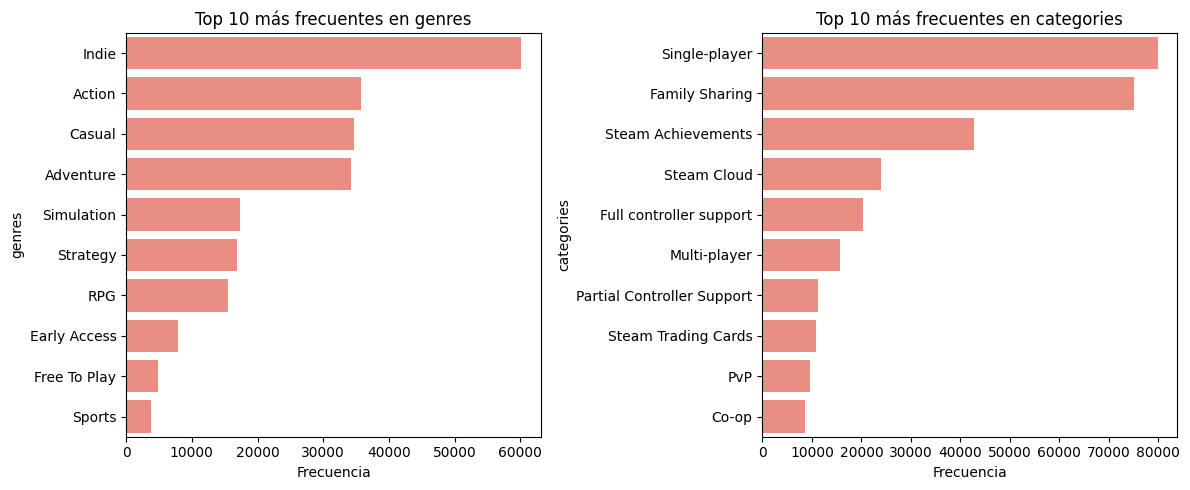

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Genres
conteo_top_generos = conteo_generos.head(10)
sns.barplot(x=conteo_top_generos.values, y=conteo_top_generos.index, color="salmon", ax=axes[0])
axes[0].set_title("Top 10 más frecuentes en genres")
axes[0].set_xlabel("Frecuencia")
axes[0].set_ylabel("genres")

# Categories
conteo_top_categorias = conteo_categorias.head(10)
sns.barplot(x=conteo_top_categorias.values, y=conteo_top_categorias.index, color="salmon", ax=axes[1])
axes[1].set_title("Top 10 más frecuentes en categories")
axes[1].set_xlabel("Frecuencia")
axes[1].set_ylabel("categories")

plt.tight_layout()
plt.show()

**Matriz de correlación**

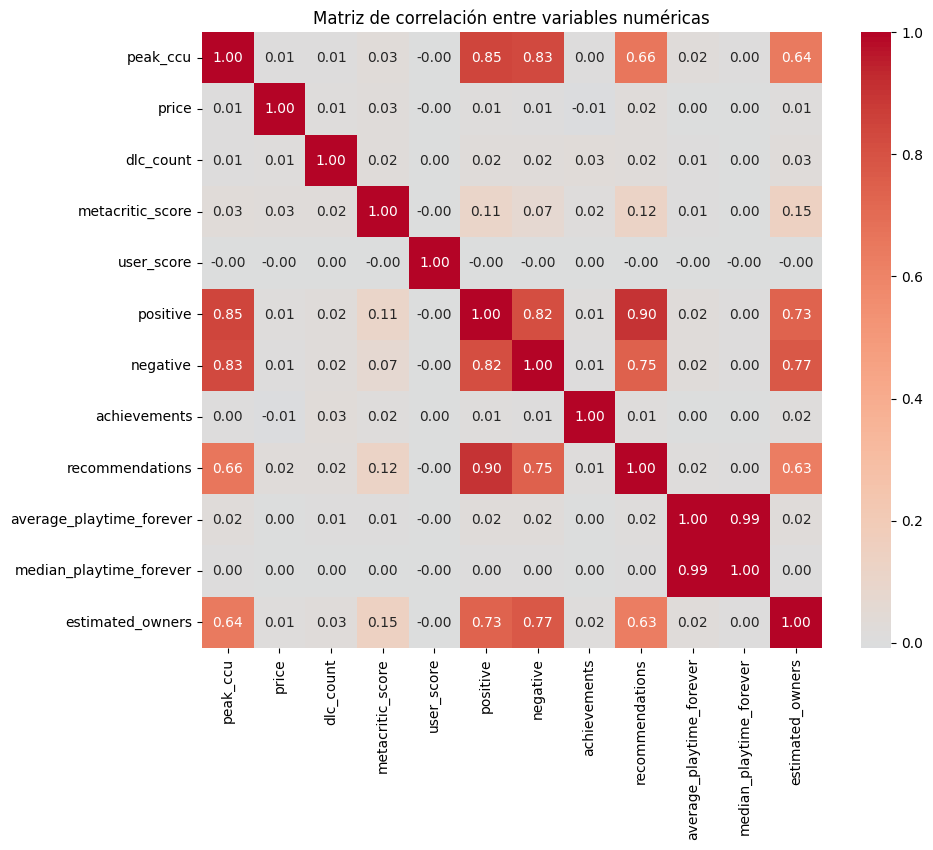

In [ ]:
columnas_numericas = ["peak_ccu", "price", "dlc_count", "metacritic_score",
                       "user_score", "positive", "negative", "achievements",
                       "recommendations", "average_playtime_forever",
                       "median_playtime_forever", "estimated_owners"]

matriz_corr = pdgames[columnas_numericas].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación entre variables numéricas")
plt.show()

**Distribución de nuestra variable objetivo**

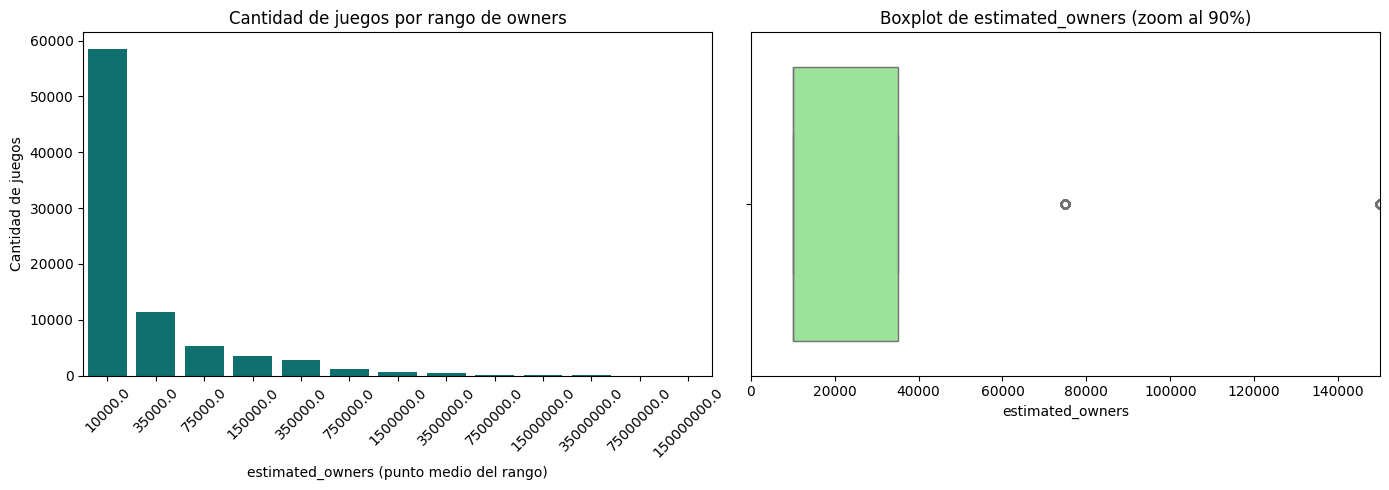

In [ ]:
limite = pdgames['estimated_owners'].quantile(0.90)
conteo_rangos = pdgames['estimated_owners'].value_counts().sort_index()

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.barplot(x=conteo_rangos.index.astype(str), y=conteo_rangos.values, color="teal")
plt.title("Cantidad de juegos por rango de owners")
plt.xlabel("estimated_owners (punto medio del rango)")
plt.ylabel("Cantidad de juegos")
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.boxplot(x=pdgames['estimated_owners'], color="lightgreen")
plt.xlim(0, limite)
plt.title("Boxplot de estimated_owners (zoom al 90%)")

plt.tight_layout()
plt.show()

**Cantidades de juegos dependiendo de variables binarias**

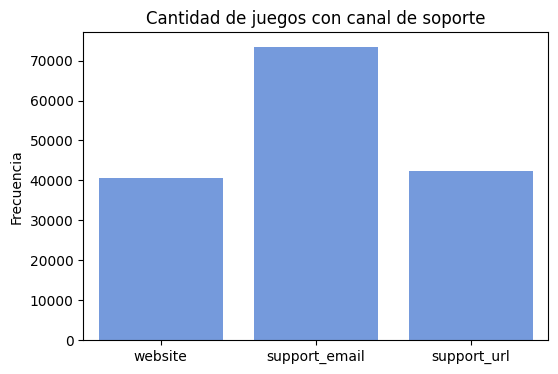

website -> 48.29%
support_email -> 87.35%
support_url -> 50.33%


In [ ]:
soporte = ["website", "support_email", "support_url"]
conteo_soporte = [pdgames[s].sum() for s in soporte]
total_juegos = len(pdgames)

plt.figure(figsize=(6, 4))
sns.barplot(x=soporte, y=conteo_soporte, color="cornflowerblue")
plt.title("Cantidad de juegos con canal de soporte")
plt.ylabel("Frecuencia")
plt.show()

for s, frecuencia in zip(soporte, conteo_soporte):
    print(f"{s} -> {frecuencia/total_juegos*100:.2f}%")

**Gráficas de bigotes**

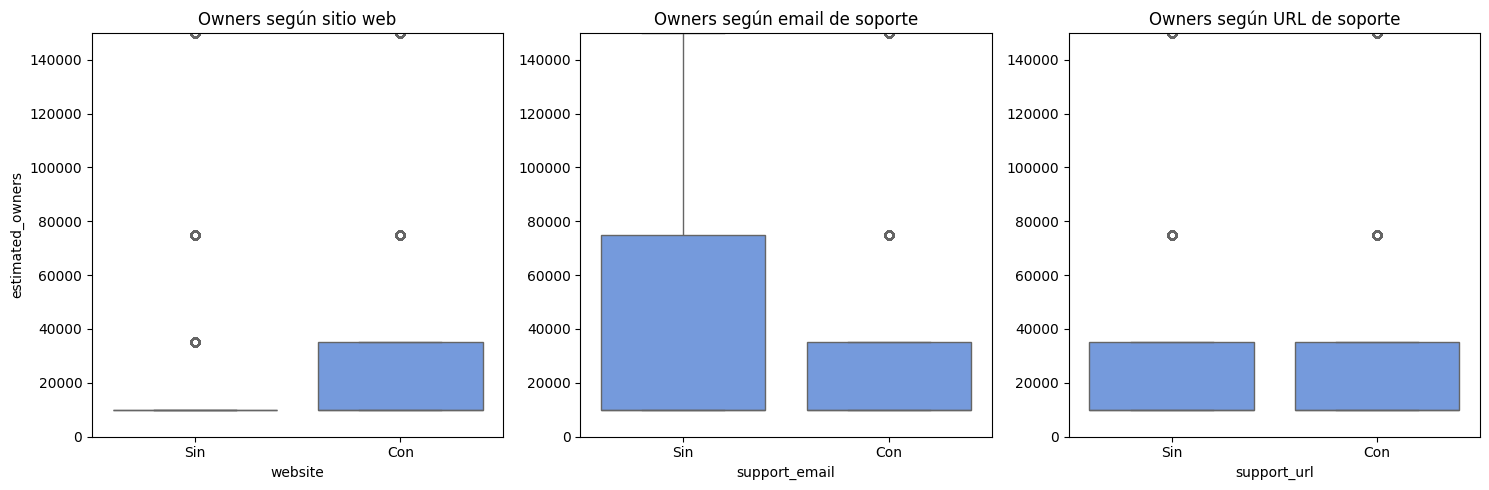

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(x='website', y='estimated_owners', data=pdgames, color="cornflowerblue", ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Sin', 'Con'])
axes[0].set_ylim(0, pdgames['estimated_owners'].quantile(0.90))
axes[0].set_title("Owners según sitio web")

sns.boxplot(x='support_email', y='estimated_owners', data=pdgames, color="cornflowerblue", ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Sin', 'Con'])
axes[1].set_ylim(0, pdgames['estimated_owners'].quantile(0.90))
axes[1].set_title("Owners según email de soporte")
axes[1].set_ylabel("")

sns.boxplot(x='support_url', y='estimated_owners', data=pdgames, color="cornflowerblue", ax=axes[2])
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Sin', 'Con'])
axes[2].set_ylim(0, pdgames['estimated_owners'].quantile(0.90))
axes[2].set_title("Owners según URL de soporte")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

**PDF Y CDF de variable objetivo y columnas altamente correlacionadas a esa variable**

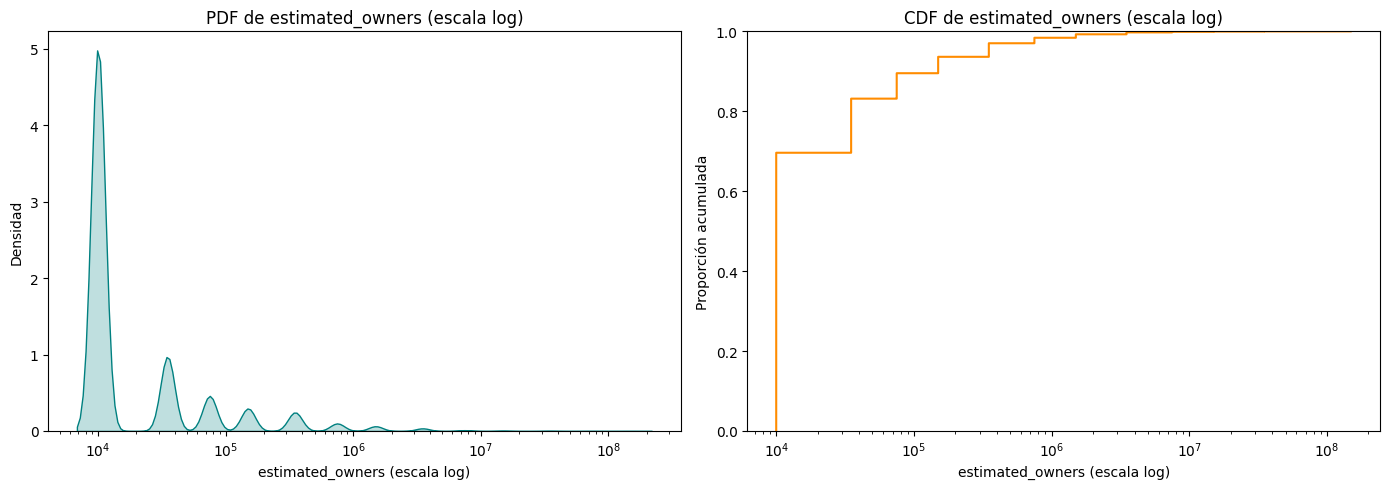

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(pdgames['estimated_owners'], fill=True, color="teal", log_scale=True, ax=axes[0])
axes[0].set_title("PDF de estimated_owners (escala log)")
axes[0].set_xlabel("estimated_owners (escala log)")
axes[0].set_ylabel("Densidad")

sns.ecdfplot(pdgames['estimated_owners'], color="darkorange", log_scale=True, ax=axes[1])
axes[1].set_title("CDF de estimated_owners (escala log)")
axes[1].set_xlabel("estimated_owners (escala log)")
axes[1].set_ylabel("Proporción acumulada")

plt.tight_layout()
plt.show()

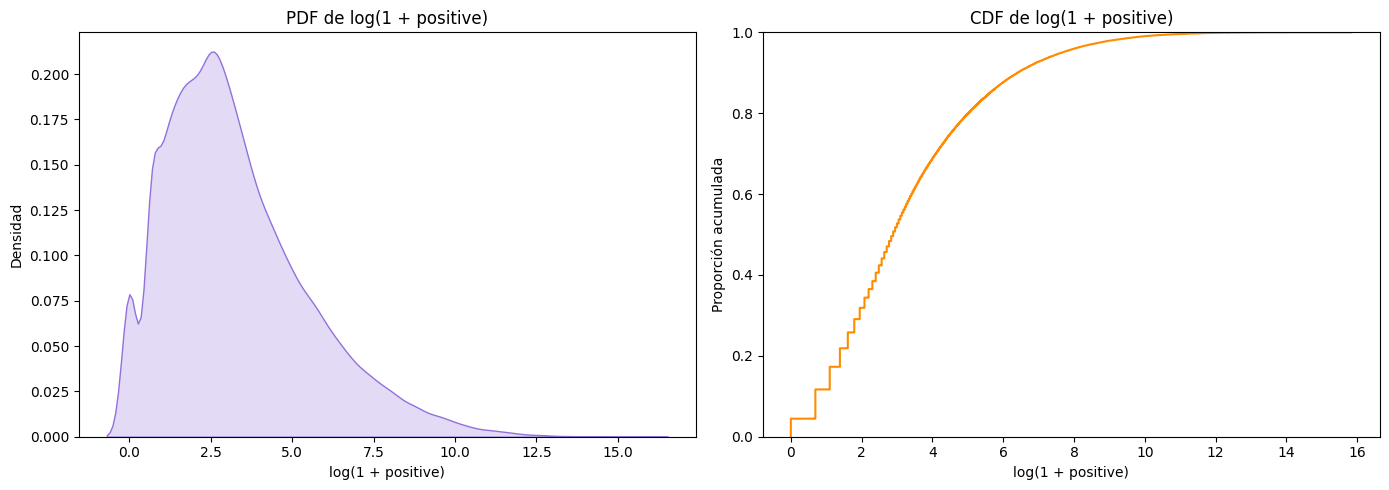

In [ ]:
positive_log = np.log1p(pdgames['positive'])  # log(1+x), maneja el 0 sin error

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(positive_log, fill=True, color="mediumpurple", ax=axes[0])
axes[0].set_title("PDF de log(1 + positive)")
axes[0].set_xlabel("log(1 + positive)")
axes[0].set_ylabel("Densidad")

sns.ecdfplot(positive_log, color="darkorange", ax=axes[1])
axes[1].set_title("CDF de log(1 + positive)")
axes[1].set_xlabel("log(1 + positive)")
axes[1].set_ylabel("Proporción acumulada")

plt.tight_layout()
plt.show()

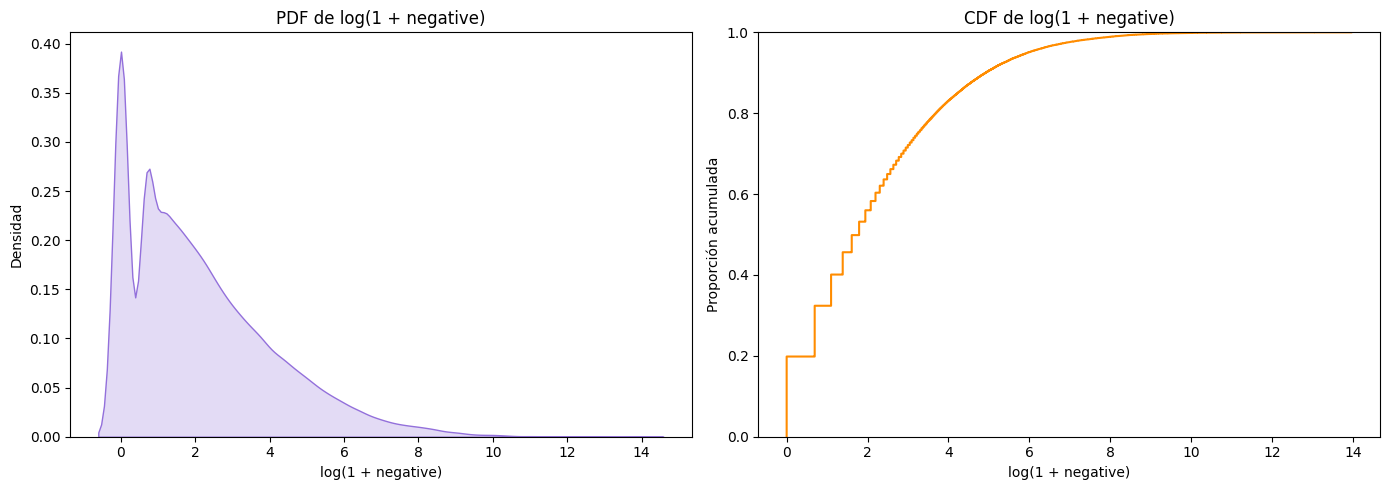

In [ ]:
negative_log = np.log1p(pdgames['negative'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(negative_log, fill=True, color="mediumpurple", ax=axes[0])
axes[0].set_title("PDF de log(1 + negative)")
axes[0].set_xlabel("log(1 + negative)")
axes[0].set_ylabel("Densidad")

sns.ecdfplot(negative_log, color="darkorange", ax=axes[1])
axes[1].set_title("CDF de log(1 + negative)")
axes[1].set_xlabel("log(1 + negative)")
axes[1].set_ylabel("Proporción acumulada")

plt.tight_layout()
plt.show()

# **AVANCE 2**

In [ ]:
datasetfinal = pdgames.copy()
datasetfinal["estimated_owners"] = datasetfinal["estimated_owners"].map({10000: 0, 35000: 1, 75000: 2, 150000: 3, 350000: 4, 750000: 5, 1500000: 6, 3500000: 6, 7500000: 6, 15000000: 6,35000000: 6, 75000000: 6, 150000000: 6})
datasetfinal = datasetfinal.drop(columns = ["name","release_date","detailed_description", "short_description", "reviews"])
print(datasetfinal.columns)
datasetfinal["genres"].head(20)

Index(['estimated_owners', 'peak_ccu', 'price', 'dlc_count', 'website',
       'support_url', 'support_email', 'windows', 'mac', 'linux',
       'metacritic_score', 'metacritic_url', 'user_score', 'positive',
       'negative', 'score_rank', 'achievements', 'recommendations',
       'average_playtime_forever', 'median_playtime_forever', 'categories',
       'genres', 'packages'],
      dtype='object')


,genres
0,[Adventure]
1,[Casual]
2,"[Casual, Indie, Simulation]"
3,"[Simulation, Strategy]"
4,"[Casual, Indie]"
5,"[Action, Casual, Indie, Strategy]"
6,"[Adventure, Indie]"
7,[Strategy]
8,"[Casual, Indie]"
9,"[Adventure, Casual, Indie]"


In [ ]:
# ---------- 1. Función para convertir a lista real ----------
def a_lista(x):
    if isinstance(x, np.ndarray):
        return [str(g).strip() for g in x.tolist()]
    if isinstance(x, (list, tuple, set)):
        return [str(g).strip() for g in x]
    if isinstance(x, str):
        x = x.strip().strip('[]').replace("'", "").replace('"', '')
        return [g.strip() for g in x.split(',') if g.strip()]
    return []

datasetfinal['categories_lista'] = datasetfinal['categories'].apply(a_lista)
datasetfinal['genres_lista'] = datasetfinal['genres'].apply(a_lista)

# ---------- 2. Grupos de categorías ----------

grupos_cat = {
    'Single_player': ['Single-player'],
    'Multiplayer': ['Multi-player', 'PvP', 'Online PvP', 'LAN PvP', 'MMO',
                    'Shared/Split Screen PvP', 'Cross-Platform Multiplayer'],
    'Coop': ['Co-op', 'Online Co-op', 'LAN Co-op', 'Shared/Split Screen Co-op',
             'Shared/Split Screen', 'Remote Play Together'],
    'Controller': ['Full controller support', 'Partial Controller Support',
                   'Tracked Controller Support', 'Touch Only Option',
                   'Mouse Only Option', 'Keyboard Only Option'],
    'Accessibility': ['Adjustable Difficulty', 'Adjustable Text Size', 'Camera Comfort',
                      'Captions available', 'Chat Speech-to-text', 'Chat Text-to-speech',
                      'Color Alternatives', 'Custom Volume Controls', 'Narrated Game Menus',
                      'Subtitle Options', 'Playable without Timed Input', 'Save Anytime',
                      'Stereo Sound', 'Surround Sound'],
    'Platafforms': ['VR Only', 'VR Support', 'VR Supported', 'SteamVR Collectibles', 'Remote Play on Phone', 'Remote Play on TV', 'Remote Play on Tablet'],
    'Steam': ['Steam Cloud', 'Steam Trading Cards', 'Steam Turn Notifications', 'Steam Achievements', 'Stats', 'Steam Leaderboards', 'Steam Timeline'],
    'Family_Sharing': ['Family Sharing'],
    'Otros': ['In-App Purchases', 'Valve Anti-Cheat enabled',
              'HDR available', 'Commentary available', 'Steam Workshop', 'Mods', 'Mods (require HL2)',
                      'Includes level editor', 'Includes Source SDK'],
}

# ---------- 3. Grupos de géneros ----------

grupos_gen = {
    'Indie': ['Indie'],
    'Action': ['Action'],
    'Casual': ['Casual'],
    'Adventure': ['Adventure'],
    'Simulation': ['Simulation'],
    'Strategy': ['Strategy'],
    'RPG': ['RPG'],
    'Sports_Racing': ['Sports', 'Racing'],
    'Mature_Content': ['Violent', 'Gore', 'Nudity', 'Sexual Content'],
    'Free to play': ['Free To Play'],
    'Otros generos': ['Early Access','Massively Multiplayer','Utilities', 'Design & Illustration', 'Animation & Modeling',
                       'Education', 'Video Production', 'Game Development',
                       'Audio Production', 'Software Training', 'Photo Editing',
                       'Web Publishing', 'Accounting', 'Movie', 'Documentary',
                       'Episodic', 'Short', 'Tutorial', '360 Video'],

}

# ---------- 4. Función que crea las columnas binarias ----------
def crear_grupos(data, col_lista, grupos, prefijo):
    for grupo, items in grupos.items():
        items_set = set(items)
        data[grupo] = data[col_lista].apply(
            lambda lst: int(any(i in items_set for i in lst))
        )
    agrupados = {i for items in grupos.values() for i in items}
    sin_grupo = set(data[col_lista].explode().dropna().unique()) - agrupados

crear_grupos(datasetfinal, 'categories_lista', grupos_cat, 'cat')
crear_grupos(datasetfinal, 'genres_lista', grupos_gen, 'gen')

In [ ]:
datasetfinal["estimated_owners"].value_counts()

,count
estimated_owners,
0,58544
1,11386
2,5352
3,3450
4,2854
6,1354
5,1154


# MODELOS DE MACHINE LEARNING

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import *
from sklearn.model_selection import *

from sklearn.naive_bayes import *
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


from sklearn.base import clone


In [ ]:
steamdf = datasetfinal.copy()
steamdf = steamdf.drop(columns = ["categories", "genres", "packages", "categories_lista", "genres_lista", "metacritic_url", "score_rank"])
steamdf["estimated_owners"] = steamdf["estimated_owners"].map({0:0, 1:0, 2:1, 3:1, 4:1, 5:1, 6:1})


variable_objetivo = steamdf.pop("estimated_owners")
steamdf["estimated_owners"] = variable_objetivo

In [ ]:
steamdf["estimated_owners"].value_counts()

,count
estimated_owners,
0,69930
1,14164


In [ ]:
X = steamdf.iloc[:,:-1]
y = steamdf.iloc[:,-1]
X_work, X_test, y_work, y_test = train_test_split(X, y, test_size=0.2, random_state=31, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_work, y_work, test_size= 0.25, random_state= 31, stratify=y_work)

In [ ]:
steamdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84094 entries, 0 to 84093
Data columns (total 38 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   peak_ccu                  84094 non-null  int64  
 1   price                     84094 non-null  float64
 2   dlc_count                 84094 non-null  int64  
 3   website                   84094 non-null  int64  
 4   support_url               84094 non-null  int64  
 5   support_email             84094 non-null  int64  
 6   windows                   84094 non-null  int64  
 7   mac                       84094 non-null  int64  
 8   linux                     84094 non-null  int64  
 9   metacritic_score          84094 non-null  int64  
 10  user_score                84094 non-null  int64  
 11  positive                  84094 non-null  int64  
 12  negative                  84094 non-null  int64  
 13  achievements              84094 non-null  int64  
 14  recomm

In [ ]:

tree = DecisionTreeClassifier()
forest = RandomForestClassifier()
# vector = make_pipeline(StandardScaler(), SVC())


# **GAUSSIAN NAIVE BAYES**

In [ ]:
resultados_gnb_train = []
resultados_gnb_test = []
for i in [1e-08, 1e-09, 1e-10]:
  gaussian = GaussianNB(var_smoothing = i)
  gaussian.fit(X_train, y_train)
  y_pred = gaussian.predict(X_val)

  cmatrix = confusion_matrix(y_val, y_pred)
  TN, FP, FN, TP = cmatrix.ravel()
  especificidad = TN / (TN + FP)

  print(f"The accuracy with var_smoothing = {i}  is:  {accuracy_score(y_val, y_pred):.3f}")
  print(f"The precision with var_smoothing = {i} is: {precision_score(y_val, y_pred, zero_division=0):.3f}")
  print(f"The recall with var_smoothing = {i} is:    {recall_score(y_val, y_pred, zero_division=0):.3f}")
  print(f"The F1 with var_smoothing = {i} is:        {f1_score(y_val, y_pred, zero_division=0):.3f}")
  print(f"The specificity {i} is: {especificidad : .3f}")
  print("")
  resultados_gnb_test.append({"var_smoothing": i, "precision": precision_score(y_val, y_pred, zero_division=0), "f1": f1_score(y_val, y_pred, zero_division=0), "specificity" : especificidad})

# El mejor Gaussian Naive Bayes es el que cuyo valor de var_smooting sea: 1e-10


print("\n\n Revisar con 'train' para estimar overfitting")
for i in [1e-08, 1e-09, 1e-10]:
  gaussian = GaussianNB(var_smoothing = i)
  gaussian.fit(X_train, y_train)
  y_pred = gaussian.predict(X_train)

  cmatrix = confusion_matrix(y_train, y_pred)
  TN, FP, FN, TP = cmatrix.ravel()
  especificidad = TN / (TN + FP)

  print(f"The accuracy with var_smoothing = {i}  is:  {accuracy_score(y_train, y_pred):.3f}")
  print(f"The precision with var_smoothing = {i} is: {precision_score(y_train, y_pred, zero_division=0):.3f}")
  print(f"The recall with var_smoothing = {i} is:    {recall_score(y_train, y_pred, zero_division=0):.3f}")
  print(f"The F1 with var_smoothing = {i} is:        {f1_score(y_train, y_pred, zero_division=0):.3f}")
  print(f"The specificity {i} is: {especificidad : .3f}")
  print("")
  resultados_gnb_train.append({"var_smoothing": i, "precision": precision_score(y_train, y_pred, zero_division=0), "f1": f1_score(y_train, y_pred, zero_division=0), "specificity" : especificidad})

resultados_train = pd.DataFrame(resultados_gnb_train)
resultados_test = pd.DataFrame(resultados_gnb_test)

The accuracy with var_smoothing = 1e-08  is:  0.864
The precision with var_smoothing = 1e-08 is: 0.765
The recall with var_smoothing = 1e-08 is:    0.274
The F1 with var_smoothing = 1e-08 is:        0.404
The specificity 1e-08 is:  0.983

The accuracy with var_smoothing = 1e-09  is:  0.864
The precision with var_smoothing = 1e-09 is: 0.763
The recall with var_smoothing = 1e-09 is:    0.277
The F1 with var_smoothing = 1e-09 is:        0.406
The specificity 1e-09 is:  0.983

The accuracy with var_smoothing = 1e-10  is:  0.865
The precision with var_smoothing = 1e-10 is: 0.768
The recall with var_smoothing = 1e-10 is:    0.283
The F1 with var_smoothing = 1e-10 is:        0.413
The specificity 1e-10 is:  0.983



 Revisar con 'train' para estimar overfitting
The accuracy with var_smoothing = 1e-08  is:  0.862
The precision with var_smoothing = 1e-08 is: 0.763
The recall with var_smoothing = 1e-08 is:    0.265
The F1 with var_smoothing = 1e-08 is:        0.394
The specificity 1e-08 is:  0.9

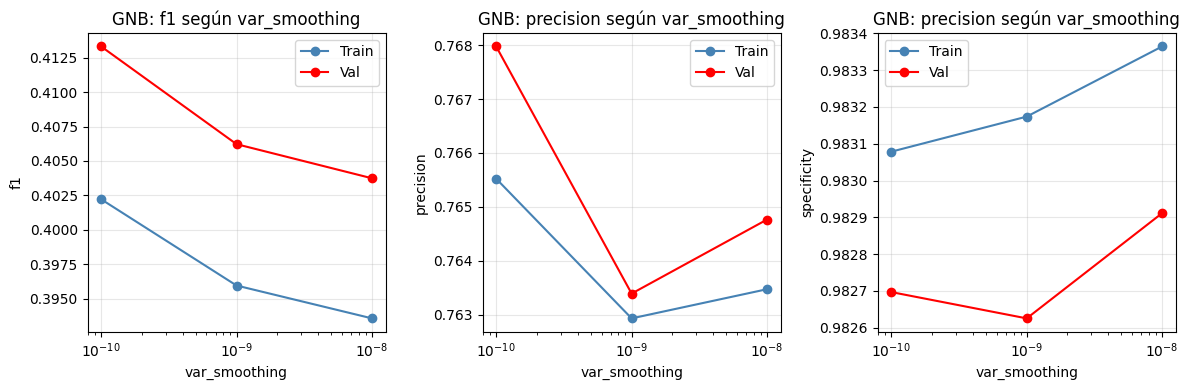

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

#f1
axes[0].plot(resultados_train["var_smoothing"], resultados_train["f1"], marker="o", color="steelblue", label="Train")
axes[0].plot(resultados_test["var_smoothing"], resultados_test["f1"], marker="o", color="red", label="Val")
axes[0].set_xscale("log")
axes[0].set_xlabel("var_smoothing")
axes[0].set_ylabel("f1")
axes[0].set_title("GNB: f1 según var_smoothing")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Precisión
axes[1].plot(resultados_train["var_smoothing"], resultados_train["precision"], marker="o", color="steelblue", label="Train")
axes[1].plot(resultados_test["var_smoothing"], resultados_test["precision"], marker="o", color="red", label="Val")
axes[1].set_xscale("log")
axes[1].set_xlabel("var_smoothing")
axes[1].set_ylabel("precision")
axes[1].set_title("GNB: precision según var_smoothing")
axes[1].grid(alpha=0.3)
axes[1].legend()

# Especificidad
axes[2].plot(resultados_train["var_smoothing"], resultados_train["specificity"], marker="o", color="steelblue", label="Train")
axes[2].plot(resultados_test["var_smoothing"], resultados_test["specificity"], marker="o", color="red", label="Val")
axes[2].set_xscale("log")
axes[2].set_xlabel("var_smoothing")
axes[2].set_ylabel("specificity")
axes[2].set_title("GNB: precision según var_smoothing")
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

# **ÁRBOLES DE DECISION**

In [ ]:
arbol_depth_test = []
arbol_split_test = []
arbol_crit_test = []

print("=== ÁRBOL: max_depth ===")
for v in [3, 5, 10, 20, None]:
    tree = DecisionTreeClassifier(max_depth=v, random_state=31)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_val)

    cmatrix = confusion_matrix(y_val, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"max_depth={v} | acc={accuracy_score(y_val, y_pred):.3f} | prec={precision_score(y_val, y_pred, zero_division=0):.3f} | rec={recall_score(y_val, y_pred, zero_division=0):.3f} | f1={f1_score(y_val, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    arbol_depth_test.append({"max_depth": str(v), "precision": precision_score(y_val, y_pred, zero_division=0), "f1": f1_score(y_val, y_pred, zero_division=0), "specificity" : especificidad})

print("\n=== ÁRBOL: min_samples_split ===")
for v in [2, 10, 50, 200]:
    tree = DecisionTreeClassifier(max_depth=5, min_samples_split=v, random_state=31)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_val)

    cmatrix = confusion_matrix(y_val, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"min_samples_split={v} | acc={accuracy_score(y_val, y_pred):.3f} | prec={precision_score(y_val, y_pred, zero_division=0):.3f} | rec={recall_score(y_val, y_pred, zero_division=0):.3f} | f1={f1_score(y_val, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    arbol_split_test.append({"min_samples_split": v, "precision": precision_score(y_val, y_pred, zero_division=0), "f1": f1_score(y_val, y_pred, zero_division=0), "specificity" : especificidad})

print("\n=== ÁRBOL: criterion ===")
for v in ["gini", "entropy", "log_loss"]:
    tree = DecisionTreeClassifier(max_depth=5, min_samples_split=50, criterion=v, random_state=31)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_val)

    cmatrix = confusion_matrix(y_val, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"criterio ={v} | acc={accuracy_score(y_val, y_pred):.3f} | prec={precision_score(y_val, y_pred, zero_division=0):.3f} | rec={recall_score(y_val, y_pred, zero_division=0):.3f} | f1={f1_score(y_val, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    arbol_crit_test.append({"criterion": v, "precision": precision_score(y_val, y_pred, zero_division=0), "f1": f1_score(y_val, y_pred, zero_division=0), "specificity" : especificidad})

#Por parte de los árboles según precisión  el mejor árbol es el que cuyos parámetros sean max_depth = 5, min_samples_split = 50 y criterio de Gini.


arbol_depth_train = []
arbol_split_train = []
arbol_crit_train = []

print("\n\nRevisar con 'train' para estimar overfitting")

print("=== ÁRBOL: max_depth ===")
for v in [3, 5, 10, 20, None]:
    tree = DecisionTreeClassifier(max_depth=v, random_state=31)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_train)

    cmatrix = confusion_matrix(y_train, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"max_depth={v} | acc={accuracy_score(y_train, y_pred):.3f} | prec={precision_score(y_train, y_pred, zero_division=0):.3f} | rec={recall_score(y_train, y_pred, zero_division=0):.3f} | f1={f1_score(y_train, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    arbol_depth_train.append({"max_depth": str(v), "precision": precision_score(y_train, y_pred, zero_division=0), "f1": f1_score(y_train, y_pred, zero_division=0), "specificity" : especificidad})

print("\n=== ÁRBOL: min_samples_split ===")
for v in [2, 10, 50, 200]:
    tree = DecisionTreeClassifier(max_depth=5, min_samples_split=v, random_state=31)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_train)

    cmatrix = confusion_matrix(y_train, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"min_samples_split={v} | acc={accuracy_score(y_train, y_pred):.3f} | prec={precision_score(y_train, y_pred, zero_division=0):.3f} | rec={recall_score(y_train, y_pred, zero_division=0):.3f} | f1={f1_score(y_train, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    arbol_split_train.append({"min_samples_split": v, "precision": precision_score(y_train, y_pred, zero_division=0), "f1": f1_score(y_train, y_pred, zero_division=0), "specificity" : especificidad})

print("\n=== ÁRBOL: criterion ===")
for v in ["gini", "entropy", "log_loss"]:
    tree = DecisionTreeClassifier(max_depth=5, min_samples_split=50, criterion=v, random_state=31)
    tree.fit(X_train, y_train)
    y_pred = tree.predict(X_train)

    cmatrix = confusion_matrix(y_train, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"criterio ={v} | acc={accuracy_score(y_train, y_pred):.3f} | prec={precision_score(y_train, y_pred, zero_division=0):.3f} | rec={recall_score(y_train, y_pred, zero_division=0):.3f} | f1={f1_score(y_train, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    arbol_crit_train.append({"criterion": v, "precision": precision_score(y_train, y_pred, zero_division=0), "f1": f1_score(y_train, y_pred, zero_division=0), "specificity" : especificidad})

arbol_depth_test = pd.DataFrame(arbol_depth_test)
arbol_depth_train = pd.DataFrame(arbol_depth_train)
arbol_split_test = pd.DataFrame(arbol_split_test)
arbol_split_train = pd.DataFrame(arbol_split_train)
arbol_crit_test = pd.DataFrame(arbol_crit_test)
arbol_crit_train = pd.DataFrame(arbol_crit_train)

=== ÁRBOL: max_depth ===
max_depth=3 | acc=0.920 | prec=0.855 | rec=0.629 | f1=0.725 | esp=0.978
max_depth=5 | acc=0.924 | prec=0.853 | rec=0.666 | f1=0.748 | esp=0.977
max_depth=10 | acc=0.918 | prec=0.809 | rec=0.670 | f1=0.733 | esp=0.968
max_depth=20 | acc=0.892 | prec=0.688 | rec=0.659 | f1=0.673 | esp=0.940
max_depth=None | acc=0.874 | prec=0.617 | rec=0.665 | f1=0.640 | esp=0.917

=== ÁRBOL: min_samples_split ===
min_samples_split=2 | acc=0.924 | prec=0.853 | rec=0.666 | f1=0.748 | esp=0.977
min_samples_split=10 | acc=0.924 | prec=0.853 | rec=0.666 | f1=0.748 | esp=0.977
min_samples_split=50 | acc=0.924 | prec=0.853 | rec=0.666 | f1=0.748 | esp=0.977
min_samples_split=200 | acc=0.924 | prec=0.852 | rec=0.662 | f1=0.745 | esp=0.977

=== ÁRBOL: criterion ===
criterio =gini | acc=0.924 | prec=0.853 | rec=0.666 | f1=0.748 | esp=0.977
criterio =entropy | acc=0.923 | prec=0.892 | rec=0.617 | f1=0.730 | esp=0.985
criterio =log_loss | acc=0.923 | prec=0.892 | rec=0.617 | f1=0.730 | esp=

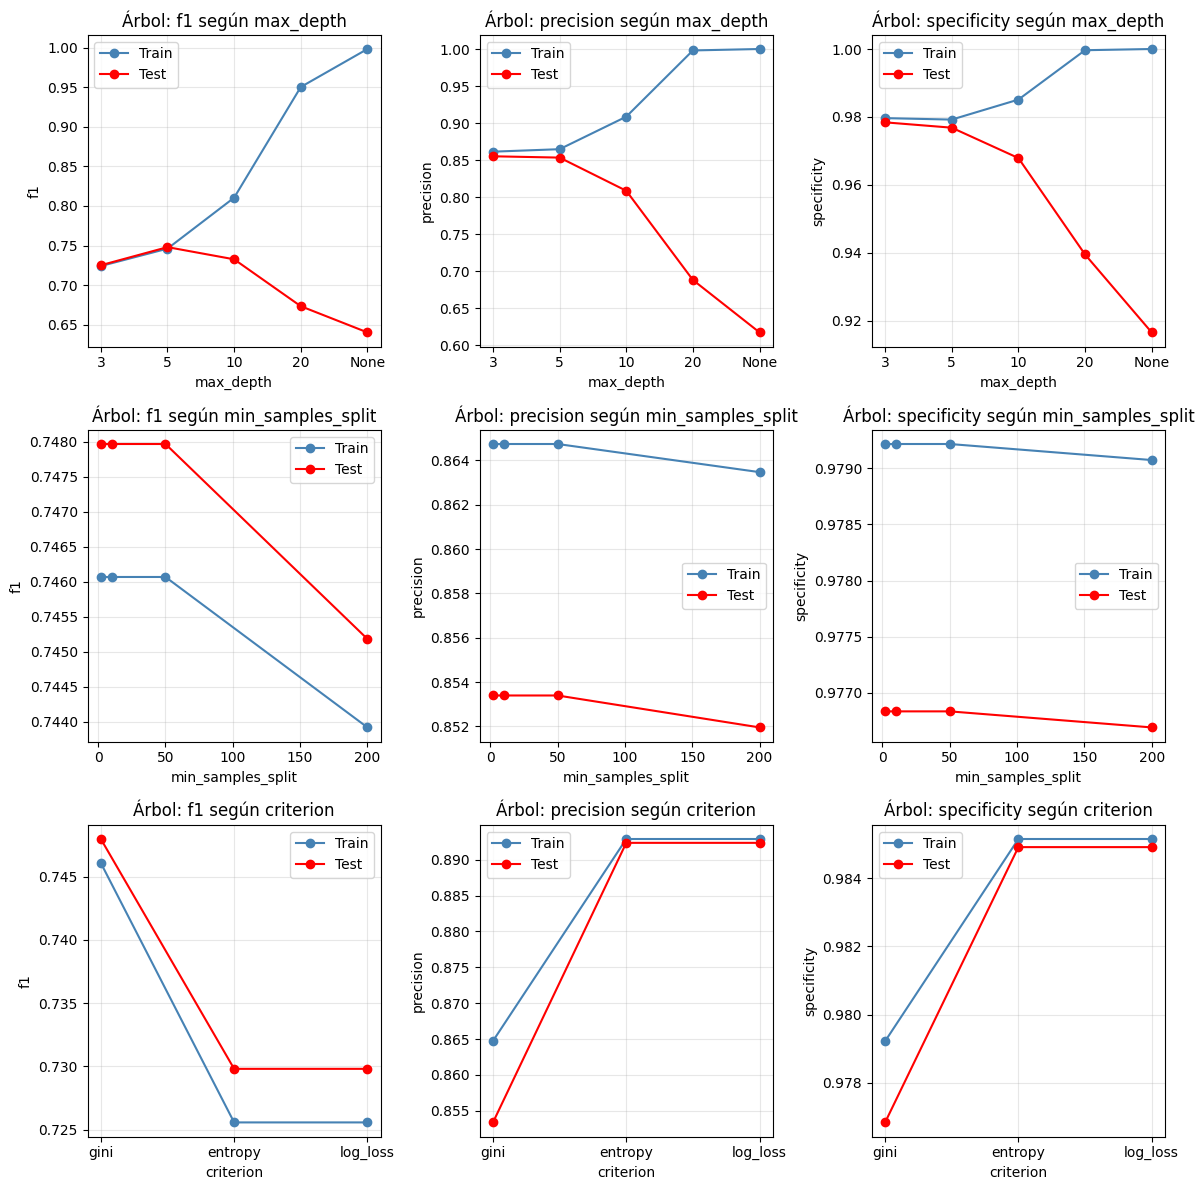

In [ ]:
hiperparametros = [("max_depth", arbol_depth_train, arbol_depth_test), ("min_samples_split", arbol_split_train, arbol_split_test),("criterion", arbol_crit_train,  arbol_crit_test),]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for fila, (param, df_train, df_test) in enumerate(hiperparametros):
    # f1
    axes[fila, 0].plot(df_train[param], df_train["f1"], marker="o", color="steelblue", label="Train")
    axes[fila, 0].plot(df_test[param], df_test["f1"], marker="o", color="red", label="Test")
    axes[fila, 0].set_xlabel(param)
    axes[fila, 0].set_ylabel("f1")
    axes[fila, 0].set_title(f"Árbol: f1 según {param}")
    axes[fila, 0].grid(alpha=0.3)
    axes[fila, 0].legend()

    # precision
    axes[fila, 1].plot(df_train[param], df_train["precision"], marker="o", color="steelblue", label="Train")
    axes[fila, 1].plot(df_test[param], df_test["precision"], marker="o", color="red", label="Test")
    axes[fila, 1].set_xlabel(param)
    axes[fila, 1].set_ylabel("precision")
    axes[fila, 1].set_title(f"Árbol: precision según {param}")
    axes[fila, 1].grid(alpha=0.3)
    axes[fila, 1].legend()

    # especificidad
    axes[fila, 2].plot(df_train[param], df_train["specificity"], marker="o", color="steelblue", label="Train")
    axes[fila, 2].plot(df_test[param], df_test["specificity"], marker="o", color="red", label="Test")
    axes[fila, 2].set_xlabel(param)
    axes[fila, 2].set_ylabel("specificity")
    axes[fila, 2].set_title(f"Árbol: specificity según {param}")
    axes[fila, 2].grid(alpha=0.3)
    axes[fila, 2].legend()

plt.tight_layout()
plt.show()

# **RANDOM FOREST**

In [ ]:
forest_est_test = []
forest_depth_test = []
forest_leaf_test = []

print("=== FOREST: n_estimators ===")
for v in [10, 50, 100, 200]:
    forest = RandomForestClassifier(n_estimators=v, random_state=31, n_jobs=-1)
    forest.fit(X_train, y_train)
    y_pred = forest.predict(X_val)

    cmatrix = confusion_matrix(y_val, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"n_estimators={v} | acc={accuracy_score(y_val, y_pred):.3f} | prec={precision_score(y_val, y_pred, zero_division=0):.3f} | rec={recall_score(y_val, y_pred, zero_division=0):.3f} | f1={f1_score(y_val, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    forest_est_test.append({"n_estimators": v, "precision": precision_score(y_val, y_pred, zero_division=0), "f1": f1_score(y_val, y_pred, zero_division=0), "specificity" : especificidad})

print("\n=== FOREST: max_depth ===")
for v in [3, 5, 10, 20, None]:
    forest = RandomForestClassifier(n_estimators=100, max_depth=v, random_state=31, n_jobs=-1)
    forest.fit(X_train, y_train)
    y_pred = forest.predict(X_val)

    cmatrix = confusion_matrix(y_val, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"max_depth={v} | acc={accuracy_score(y_val, y_pred):.3f} | prec={precision_score(y_val, y_pred, zero_division=0):.3f} | rec={recall_score(y_val, y_pred, zero_division=0):.3f} | f1={f1_score(y_val, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    forest_depth_test.append({"max_depth": str(v), "precision": precision_score(y_val, y_pred, zero_division=0), "f1": f1_score(y_val, y_pred, zero_division=0), "specificity" : especificidad})

print("\n=== FOREST: min_samples_leaf ===")
for v in [2, 10, 50, 200]:
    forest = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=v, random_state=31, n_jobs=-1)
    forest.fit(X_train, y_train)
    y_pred = forest.predict(X_val)

    cmatrix = confusion_matrix(y_val, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"min_samples_leaf={v} | acc={accuracy_score(y_val, y_pred):.3f} | prec={precision_score(y_val, y_pred, zero_division=0):.3f} | rec={recall_score(y_val, y_pred, zero_division=0):.3f} | f1={f1_score(y_val, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    forest_leaf_test.append({"min_samples_leaf": v, "precision": precision_score(y_val, y_pred, zero_division=0), "f1": f1_score(y_val, y_pred, zero_division=0), "specificity" : especificidad})

#Por parte de los bosques aleatorios según precisión  el mejor bosque es el que cuyos parámetros sean n_estimators =  , max_depth =  y min_samples_leaf = .


forest_est_train = []
forest_depth_train = []
forest_leaf_train = []

print("\n\nRevisar con 'train' para estimar overfitting")
print("=== FOREST: n_estimators ===")
for v in [10, 50, 100, 200]:
    forest = RandomForestClassifier(n_estimators=v, random_state=31, n_jobs=-1)
    forest.fit(X_train, y_train)
    y_pred = forest.predict(X_train)

    cmatrix = confusion_matrix(y_train, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"n_estimators={v} | acc={accuracy_score(y_train, y_pred):.3f} | prec={precision_score(y_train, y_pred, zero_division=0):.3f} | rec={recall_score(y_train, y_pred, zero_division=0):.3f} | f1={f1_score(y_train, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    forest_est_train.append({"n_estimators": v, "precision": precision_score(y_train, y_pred, zero_division=0), "f1": f1_score(y_train, y_pred, zero_division=0), "specificity" : especificidad})

print("\n=== FOREST: max_depth ===")
for v in [3, 5, 10, 20, None]:
    forest = RandomForestClassifier(n_estimators=100, max_depth=v, random_state=31, n_jobs=-1)
    forest.fit(X_train, y_train)
    y_pred = forest.predict(X_train)

    cmatrix = confusion_matrix(y_train, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"max_depth={v} | acc={accuracy_score(y_train, y_pred):.3f} | prec={precision_score(y_train, y_pred, zero_division=0):.3f} | rec={recall_score(y_train, y_pred, zero_division=0):.3f} | f1={f1_score(y_train, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    forest_depth_train.append({"max_depth": str(v), "precision": precision_score(y_train, y_pred, zero_division=0), "f1": f1_score(y_train, y_pred, zero_division=0), "specificity" : especificidad})

print("\n=== FOREST: min_samples_leaf ===")
for v in [2, 10, 50, 200]:
    forest = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=v, random_state=31, n_jobs=-1)
    forest.fit(X_train, y_train)
    y_pred = forest.predict(X_train)

    cmatrix = confusion_matrix(y_train, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    print(f"min_samples_leaf={v} | acc={accuracy_score(y_train, y_pred):.3f} | prec={precision_score(y_train, y_pred, zero_division=0):.3f} | rec={recall_score(y_train, y_pred, zero_division=0):.3f} | f1={f1_score(y_train, y_pred, zero_division=0):.3f} | esp={especificidad :.3f}")
    forest_leaf_train.append({"min_samples_leaf": v, "precision": precision_score(y_train, y_pred, zero_division=0), "f1": f1_score(y_train, y_pred, zero_division=0), "specificity" : especificidad})

forest_est_test = pd.DataFrame(forest_est_test)
forest_est_train = pd.DataFrame(forest_est_train)
forest_depth_test = pd.DataFrame(forest_depth_test)
forest_depth_train = pd.DataFrame(forest_depth_train)
forest_leaf_test = pd.DataFrame(forest_leaf_test)
forest_leaf_train = pd.DataFrame(forest_leaf_train)

=== FOREST: n_estimators ===
n_estimators=10 | acc=0.924 | prec=0.862 | rec=0.653 | f1=0.743 | esp=0.979
n_estimators=50 | acc=0.929 | prec=0.868 | rec=0.683 | f1=0.765 | esp=0.979
n_estimators=100 | acc=0.931 | prec=0.871 | rec=0.690 | f1=0.770 | esp=0.979
n_estimators=200 | acc=0.930 | prec=0.865 | rec=0.690 | f1=0.768 | esp=0.978

=== FOREST: max_depth ===
max_depth=3 | acc=0.919 | prec=0.872 | rec=0.607 | f1=0.716 | esp=0.982
max_depth=5 | acc=0.925 | prec=0.875 | rec=0.647 | f1=0.744 | esp=0.981
max_depth=10 | acc=0.929 | prec=0.874 | rec=0.678 | f1=0.764 | esp=0.980
max_depth=20 | acc=0.930 | prec=0.870 | rec=0.688 | f1=0.768 | esp=0.979
max_depth=None | acc=0.931 | prec=0.871 | rec=0.690 | f1=0.770 | esp=0.979

=== FOREST: min_samples_leaf ===
min_samples_leaf=2 | acc=0.929 | prec=0.872 | rec=0.680 | f1=0.764 | esp=0.980
min_samples_leaf=10 | acc=0.929 | prec=0.873 | rec=0.675 | f1=0.762 | esp=0.980
min_samples_leaf=50 | acc=0.927 | prec=0.866 | rec=0.669 | f1=0.755 | esp=0.979


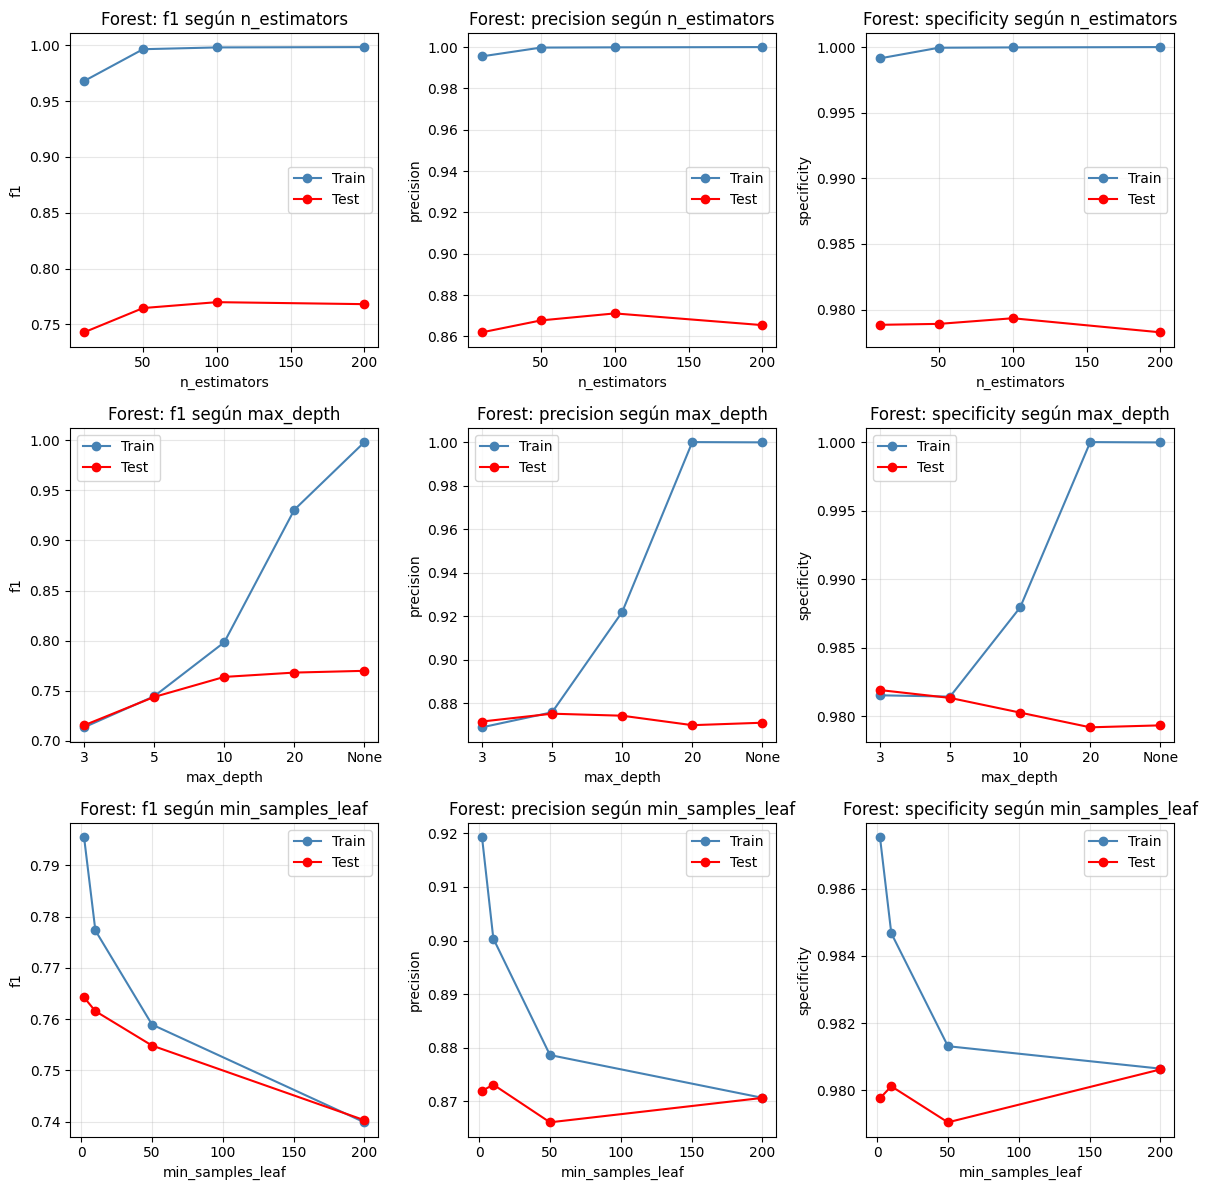

In [ ]:
hiperparametros = [("n_estimators",     forest_est_train,   forest_est_test),("max_depth",forest_depth_train, forest_depth_test),("min_samples_leaf", forest_leaf_train,  forest_leaf_test),]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for fila, (param, df_train, df_test) in enumerate(hiperparametros):
    # F1
    axes[fila, 0].plot(df_train[param], df_train["f1"], marker="o", color="steelblue", label="Train")
    axes[fila, 0].plot(df_test[param], df_test["f1"], marker="o", color="red", label="Test")
    axes[fila, 0].set_xlabel(param)
    axes[fila, 0].set_ylabel("f1")
    axes[fila, 0].set_title(f"Forest: f1 según {param}")
    axes[fila, 0].grid(alpha=0.3)
    axes[fila, 0].legend()

    # Precision
    axes[fila, 1].plot(df_train[param], df_train["precision"], marker="o", color="steelblue", label="Train")
    axes[fila, 1].plot(df_test[param], df_test["precision"], marker="o", color="red", label="Test")
    axes[fila, 1].set_xlabel(param)
    axes[fila, 1].set_ylabel("precision")
    axes[fila, 1].set_title(f"Forest: precision según {param}")
    axes[fila, 1].grid(alpha=0.3)
    axes[fila, 1].legend()

    # especificidad
    axes[fila, 2].plot(df_train[param], df_train["specificity"], marker="o", color="steelblue", label="Train")
    axes[fila, 2].plot(df_test[param], df_test["specificity"], marker="o", color="red", label="Test")
    axes[fila, 2].set_xlabel(param)
    axes[fila, 2].set_ylabel("specificity")
    axes[fila, 2].set_title(f"Forest: specificity según {param}")
    axes[fila, 2].grid(alpha=0.3)
    axes[fila, 2].legend()

plt.tight_layout()
plt.show()

# **SUPPORT VECTOR MACHINE**

---

In [ ]:
# print("=== SVM: C ===")
# for v in [0.1, 1, 10]:
#     vector = make_pipeline(StandardScaler(), SVC(C=v))
#     vector.fit(X_train, y_train)
#     y_pred = vector.predict(X_val)
#     print(f"C={v} | acc={accuracy_score(y_val, y_pred):.3f} | prec={precision_score(y_val, y_pred, zero_division=0):.3f} | rec={recall_score(y_val, y_pred, zero_division=0):.3f} | f1={f1_score(y_val, y_pred, zero_division=0):.3f}")

# print("\n=== SVM: kernel ===")
# for v in ["linear", "rbf", "sigmoid"]:
#     vector = make_pipeline(StandardScaler(), SVC(C=10, kernel=v))
#     vector.fit(X_train, y_train)
#     y_pred = vector.predict(X_val)
#     print(f"kernel={v} | acc={accuracy_score(y_val, y_pred):.3f} | prec={precision_score(y_val, y_pred, zero_division=0):.3f} | rec={recall_score(y_val, y_pred, zero_division=0):.3f} | f1={f1_score(y_val, y_pred, zero_division=0):.3f}")

# print("\n=== SVM: gamma ===")
# for v in ["scale", "auto", 0.01]:
#     vector = make_pipeline(StandardScaler(), SVC(C=10, kernel="linear", gamma=v))
#     vector.fit(X_train, y_train)
#     y_pred = vector.predict(X_val)
#     print(f"gamma={v} | acc={accuracy_score(y_val, y_pred):.3f} | prec={precision_score(y_val, y_pred, zero_division=0):.3f} | rec={recall_score(y_val, y_pred, zero_division=0):.3f} | f1={f1_score(y_val, y_pred, zero_division=0):.3f}")

# # El mejor SVM es aquel que sus hiperparámetros son: C = , kernel =  y gamma: .


# """
# print("\n\n\Revisar con 'train' para estimar overfitting")
# for v in [0.1, 1, 10]:
#     vector = make_pipeline(StandardScaler(), SVC(C=v))
#     vector.fit(X_train, y_train)
#     y_pred = vector.predict(X_train)
#     print(f"C={v} | acc={accuracy_score(y_train, y_pred):.3f} | prec={precision_score(y_train, y_pred, zero_division=0):.3f} | rec={recall_score(y_train, y_pred, zero_division=0):.3f} | f1={f1_score(y_train, y_pred, zero_division=0):.3f}")

# print("\n=== SVM: kernel ===")
# for v in ["linear", "rbf", "sigmoid"]:
#     vector = make_pipeline(StandardScaler(), SVC(C=10, kernel=v))
#     vector.fit(X_train, y_train)
#     y_pred = vector.predict(X_train)
#     print(f"kernel={v} | acc={accuracy_score(y_train, y_pred):.3f} | prec={precision_score(y_train, y_pred, zero_division=0):.3f} | rec={recall_score(y_train, y_pred, zero_division=0):.3f} | f1={f1_score(y_train, y_pred, zero_division=0):.3f}")

# print("\n=== SVM: gamma ===")
# for v in ["scale", "auto", 0.01]:
#     vector = make_pipeline(StandardScaler(), SVC(C=10, kernel="linear", gamma=v))
#     vector.fit(X_train, y_train)
#     y_pred = vector.predict(X_train)
#     print(f"gamma={v} | acc={accuracy_score(y_train, y_pred):.3f} | prec={precision_score(y_train, y_pred, zero_division=0):.3f} | rec={recall_score(y_train, y_pred, zero_division=0):.3f} | f1={f1_score(y_train, y_pred, zero_division=0):.3f}")ç

# """

# **PUNTO 4: GRÁFICAS DE LA EXPLORACIÓN DE HIPERPARÁMETROS**

En esta parte se repiten las mismas exploraciones del punto 3 (mismos valores y mismo random_state), pero ahora guardando los resultados para poder graficarlos.

Todas las métricas se miden en el conjunto de validación (X_val) y la clase positiva es la 1. Esta representa "juegos populares"

En cada gráfica la línea roja gruesa es el F1, la azul es la precisión y la verde es el recall. La línea gris punteada marca el valor que elegimos.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Hiperparámetros que elegimos en el punto 3 (se dejan aquí para usarlos en todo lo que sigue)
gnb_var_smoothing = 1e-10

arbol_max_depth = 5
arbol_min_samples_split = 200
arbol_criterion = "entropy"

bosque_n_estimators = 200
bosque_max_depth = 10
bosque_min_samples_leaf = 2

# svm_C = 10
# svm_kernel = "linear"
# svm_gamma = "scale"


def evaluar(modelo):
    # Entrena el modelo con train y lo prueba con validación
    # Devuelve el F1, la precisión y el recall
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_val)

    cmatrix = confusion_matrix(y_test, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()

    f1 = f1_score(y_val, y_pred, zero_division=0)
    prec = precision_score(y_val, y_pred, zero_division=0)
    rec = recall_score(y_val, y_pred, zero_division=0)
    especificidad = TN / (TN + FP)

    return f1, prec, rec, especificidad


def graficar(ax, valores, resultados, titulo, elegido):
    # ax es el cuadro donde se dibuja la gráfica
    # valores son los valores del hiperparámetro que probamos
    # resultados es la lista con (f1, precisión, recall) de cada valor
    # elegido es el valor que escogimos al final
    resultados = np.array(resultados)         # se pasa a array para poder sacar columnas
    posiciones = list(range(len(valores)))    # 0, 1, 2... para que los valores queden separados parejo
    etiquetas = [str(v) for v in valores]     # los valores pasados a texto para ponerlos en el eje x

    ax.plot(posiciones, resultados[:, 0], marker="o", linewidth=3, color="red", label="F1")
    ax.plot(posiciones, resultados[:, 1], marker="s", color="blue", label="Precisión")
    ax.plot(posiciones, resultados[:, 2], marker="^", color="green", label="Recall")
    ax.plot(posiciones, resultados[:, 3], marker=">", color="magenta", label="Especificidad")

    # Línea vertical punteada en el valor elegido
    if str(elegido) in etiquetas:
        ax.axvline(etiquetas.index(str(elegido)), color="gray", linestyle="--", label="Valor elegido")

    ax.set_xticks(posiciones)
    ax.set_xticklabels(etiquetas)
    ax.set_title(titulo)
    ax.set_xlabel("Valor probado")
    ax.set_ylabel("Métrica en validación")
    ax.legend(fontsize=8, framealpha=0.8)
    ax.grid(True, alpha=0.3)


## Gaussian Naive Bayes


Explorando Gaussian Naive Bayes



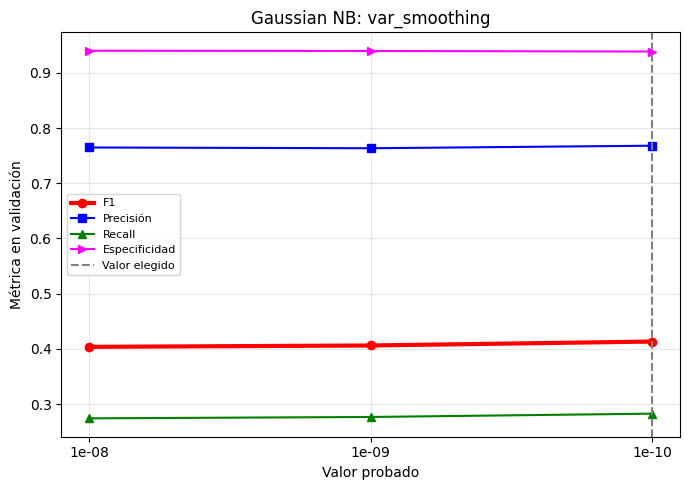

In [ ]:
print("\nExplorando Gaussian Naive Bayes\n")

valores_smoothing = [1e-08, 1e-09, 1e-10]
resultados_smoothing = []

for v in valores_smoothing:
    gaussian = GaussianNB(var_smoothing=v)
    resultados_smoothing.append(evaluar(gaussian))

fig, ax = plt.subplots(figsize=(7, 5))
graficar(ax, valores_smoothing, resultados_smoothing, "Gaussian NB: var_smoothing", gnb_var_smoothing)
plt.tight_layout()
plt.show()


## Árboles de decisión


Explorando árboles de decisión



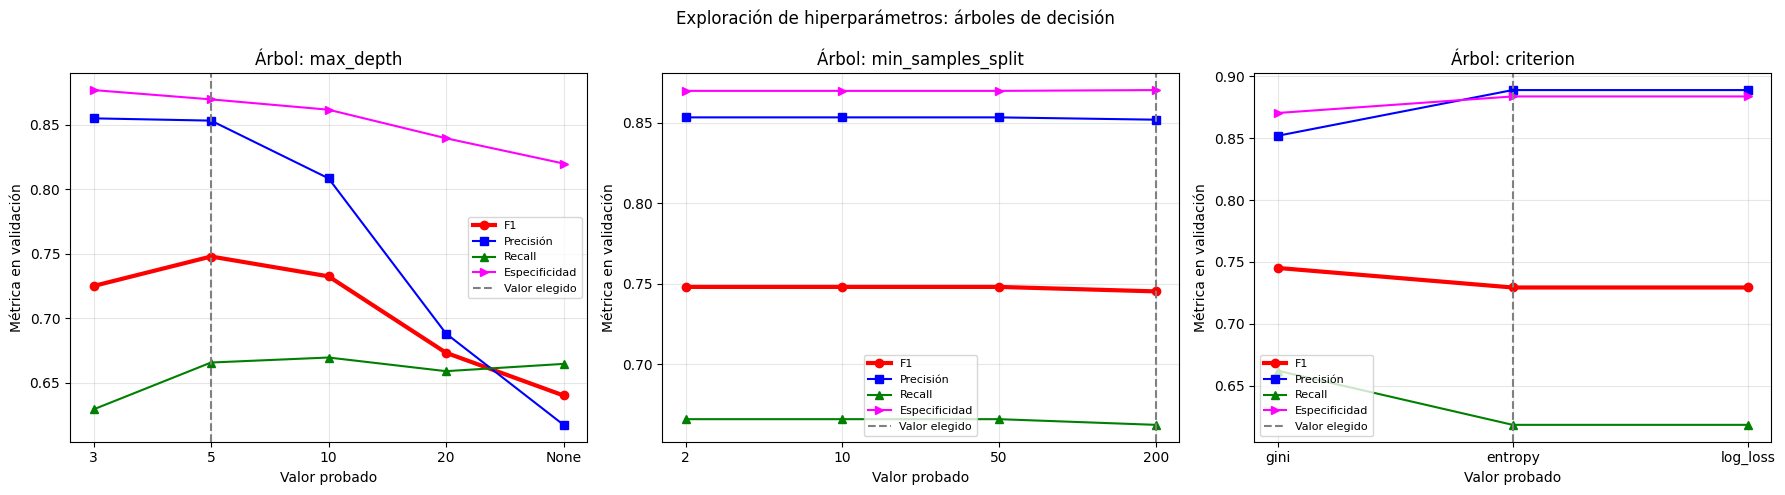

In [ ]:
print("\nExplorando árboles de decisión\n")

# max_depth (lo demás en valores por defecto)
valores_depth = [3, 5, 10, 20, None]
resultados_depth = []
for v in valores_depth:
    arbol = DecisionTreeClassifier(max_depth=v, random_state=31)
    resultados_depth.append(evaluar(arbol))

# min_samples_split (con max_depth = 5, igual que en el punto 3)
valores_split = [2, 10, 50, 200]
resultados_split = []
for v in valores_split:
    arbol = DecisionTreeClassifier(max_depth=5, min_samples_split=v, random_state=31)
    resultados_split.append(evaluar(arbol))

# criterion (con max_depth = 5 y min_samples_split = 200, igual que en el punto 3)
# En sklearn entropy y log_loss son lo mismo, por eso dan resultados idénticos
valores_criterio = ["gini", "entropy", "log_loss"]
resultados_criterio = []
for v in valores_criterio:
    arbol = DecisionTreeClassifier(max_depth=5, min_samples_split=200, criterion=v, random_state=31)
    resultados_criterio.append(evaluar(arbol))

# Las 3 gráficas en una sola fila
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
graficar(axes[0], valores_depth, resultados_depth, "Árbol: max_depth", arbol_max_depth)
graficar(axes[1], valores_split, resultados_split, "Árbol: min_samples_split", arbol_min_samples_split)
graficar(axes[2], valores_criterio, resultados_criterio, "Árbol: criterion", arbol_criterion)
plt.suptitle("Exploración de hiperparámetros: árboles de decisión")
plt.tight_layout()
plt.show()


## Random Forest


Explorando Random Forest



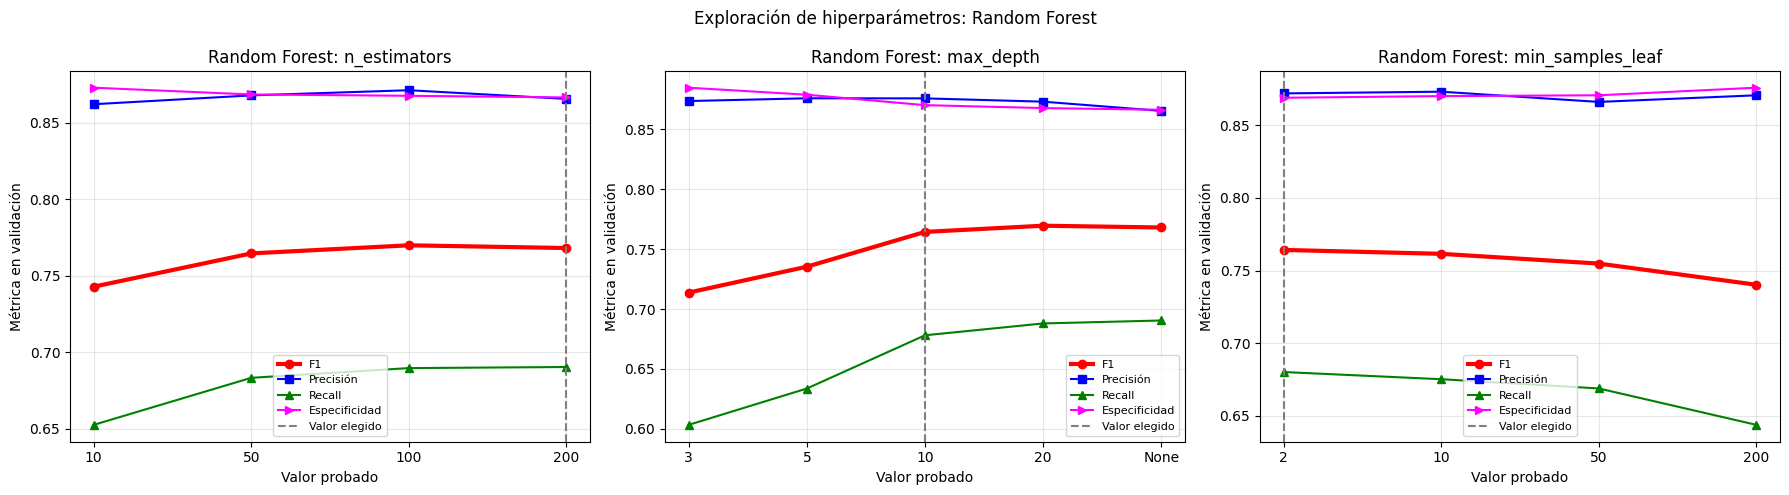

In [ ]:
print("\nExplorando Random Forest\n")

# n_estimators (lo demás en valores por defecto)
valores_estimators = [10, 50, 100, 200]
resultados_estimators = []
for v in valores_estimators:
    bosque = RandomForestClassifier(n_estimators=v, random_state=31, n_jobs=-1)
    resultados_estimators.append(evaluar(bosque))

# max_depth (con n_estimators = 200, igual que en el punto 3)
valores_depth_bosque = [3, 5, 10, 20, None]
resultados_depth_bosque = []
for v in valores_depth_bosque:
    bosque = RandomForestClassifier(n_estimators=200, max_depth=v, random_state=31, n_jobs=-1)
    resultados_depth_bosque.append(evaluar(bosque))

# min_samples_leaf (con n_estimators = 200 y max_depth = 10, igual que en el punto 3)
valores_leaf = [2, 10, 50, 200]
resultados_leaf = []
for v in valores_leaf:
    bosque = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=v, random_state=31, n_jobs=-1)
    resultados_leaf.append(evaluar(bosque))

# Las 3 gráficas en una sola fila
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
graficar(axes[0], valores_estimators, resultados_estimators, "Random Forest: n_estimators", bosque_n_estimators)
graficar(axes[1], valores_depth_bosque, resultados_depth_bosque, "Random Forest: max_depth", bosque_max_depth)
graficar(axes[2], valores_leaf, resultados_leaf, "Random Forest: min_samples_leaf", bosque_min_samples_leaf)
plt.suptitle("Exploración de hiperparámetros: Random Forest")
plt.tight_layout()
plt.show()


## Support Vector Machine

In [ ]:
# print("\nExplorando SVM. Esta es la parte más lenta, puede tardar varios minutos\n")

# # C (lo demás en valores por defecto)
# valores_C = [0.1, 1, 10]
# resultados_C = []
# for v in valores_C:
#     svm = make_pipeline(StandardScaler(), SVC(C=v))
#     resultados_C.append(evaluar(svm))
# print("Listo el barrido de C")

# # kernel (con C = 10, igual que en el punto 3)
# valores_kernel = ["linear", "rbf", "sigmoid"]
# resultados_kernel = []
# for v in valores_kernel:
#     svm = make_pipeline(StandardScaler(), SVC(C=10, kernel=v))
#     resultados_kernel.append(evaluar(svm))
# print("Listo el barrido de kernel")

# # gamma (con C = 10 y kernel lineal, igual que en el punto 3)
# # Con kernel lineal gamma no se usa, por eso se espera una línea plana
# valores_gamma = ["scale", "auto", 0.01]
# resultados_gamma = []
# for v in valores_gamma:
#     svm = make_pipeline(StandardScaler(), SVC(C=10, kernel="linear", gamma=v))
#     resultados_gamma.append(evaluar(svm))
# print("Listo el barrido de gamma")

# # Las 3 gráficas en una sola fila
# fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# graficar(axes[0], valores_C, resultados_C, "SVM: C", svm_C)
# graficar(axes[1], valores_kernel, resultados_kernel, "SVM: kernel", svm_kernel)
# graficar(axes[2], valores_gamma, resultados_gamma, "SVM: gamma", svm_gamma)
# plt.suptitle("Exploración de hiperparámetros: SVM")
# plt.tight_layout()
# plt.show()


# **PUNTO 5: MODELOS AJUSTADOS CON LOS MEJORES HIPERPARÁMETROS (2 CLASES)**

Se entrenan los 4 modelos con los hiperparámetros elegidos y se comparan en el conjunto de validación.

El criterio para ordenarlos es primero el F1 y, si hay empate, la precisión.

In [ ]:
# Los 4 modelos con sus mejores hiperparámetros (los valores salen de la celda del punto 4)
modelos = {
    "Gaussian NB": GaussianNB(var_smoothing=gnb_var_smoothing),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=arbol_max_depth,
                                                min_samples_split=arbol_min_samples_split,
                                                criterion=arbol_criterion,
                                                random_state=31),
    "Random Forest": RandomForestClassifier(n_estimators=bosque_n_estimators,
                                            max_depth=bosque_max_depth,
                                            min_samples_leaf=bosque_min_samples_leaf,
                                            random_state=31,
                                            n_jobs=-1),
#     "SVM": make_pipeline(StandardScaler(), SVC(C=svm_C, kernel=svm_kernel, gamma=svm_gamma)),
}

filas = []   # aquí se guardan los resultados de cada modelo

for nombre, modelo in modelos.items():
    print("\nEntrenando:", nombre)
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_val)

    cmatrix = confusion_matrix(y_test, y_pred)
    TN, FP, FN, TP = cmatrix.ravel()
    especificidad = TN / (TN + FP)

    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred, zero_division=0)
    rec = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)
    filas.append([nombre, acc, prec, rec, f1, especificidad])

# Se arma la tabla de resultados
tabla = pd.DataFrame(filas, columns=["Modelo", "Accuracy", "Precision", "Recall", "F1", "Especificidad"])

# Se redondea a 3 decimales (como en los prints anteriores) para que el desempate por precisión sea justo
tabla = tabla.round(3)

# Se ordena de mejor a peor: primero por F1 y si empatan por Precision
tabla = tabla.sort_values(by=["F1", "Precision"], ascending=False).reset_index(drop=True)

print("\n\nResultados en validación, ordenados de mejor a peor:\n")
print(tabla)

# Los 2 mejores modelos
mejores_2 = tabla["Modelo"].head(2).tolist()

print("\n\nEl mejor modelo es:", mejores_2[0])
print("El segundo mejor modelo es:", mejores_2[1])
print("\nEstos 2 modelos pasan a la clasificación multiclase\n")



Entrenando: Gaussian NB

Entrenando: Árbol de decisión

Entrenando: Random Forest


Resultados en validación, ordenados de mejor a peor:

              Modelo  Accuracy  Precision  Recall     F1  Especificidad
0      Random Forest     0.929      0.872   0.680  0.764          0.869
1  Árbol de decisión     0.923      0.889   0.618  0.729          0.884
2        Gaussian NB     0.865      0.768   0.283  0.413          0.939


El mejor modelo es: Random Forest
El segundo mejor modelo es: Árbol de decisión

Estos 2 modelos pasan a la clasificación multiclase



# **PUNTO 6: CLASIFICACIÓN MULTICLASE CON LOS 2 MEJORES MODELOS**

Se usan los 2 mejores modelos del punto 5 con los mismos hiperparámetros, pero ahora para predecir las 7 clases originales de estimated_owners (0 a 6).

Se usan las mismas filas de train y test que en el caso de 2 clases. El conjunto de test se usa aquí

Como ahora hay más de 2 clases, F1, precisión y recall se calculan con el promedio macro (promedio simple de las 7 clases).

In [ ]:
# La variable objetivo de 7 clases sigue en datasetfinal (en steamdf ya está agrupada en 2 clases)
y_multi = datasetfinal["estimated_owners"]

# Con el índice se sacan exactamente las mismas filas de train y test que en el caso de 2 clases
y_train_multi = y_multi.loc[X_train.index]
y_test_multi = y_multi.loc[X_test.index]

print("\nCantidad de juegos por clase en el dataset completo:\n")
print(y_multi.value_counts().sort_index())

filas_multi = []   # aquí se guardan las métricas de cada modelo
predicciones = []  # aquí se guardan las predicciones para la matriz de confusión

for nombre in mejores_2:
    print("\n\nEntrenando para multiclase:", nombre, "\n")

    # clone crea una copia nueva (sin entrenar) del modelo con los mismos hiperparámetros
    modelo = clone(modelos[nombre])
    modelo.fit(X_train, y_train_multi)
    y_pred = modelo.predict(X_test)
    predicciones.append(y_pred)

    cm = confusion_matrix(y_test, y_pred)
    tp = np.diag(cm)
    fp = np.sum(cm, axis=0) - tp
    fn = np.sum(cm, axis=0) - tp
    tn = np.sum(cm, axis=0) - (tp+fp+fn)

    esp = tn / (tn + fp)

    acc = accuracy_score(y_test_multi, y_pred)
    prec = precision_score(y_test_multi, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_test_multi, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test_multi, y_pred, average="macro", zero_division=0)
    filas_multi.append([nombre, acc, prec, rec, f1, esp])

    print("Resultados por clase de", nombre, ":\n")
    print(classification_report(y_test_multi, y_pred, zero_division=0))

# Tabla resumen de los 2 modelos (mismo orden: primero F1 y luego Precision)
tabla_multi = pd.DataFrame(filas_multi, columns=["Modelo", "Accuracy", "Precision macro", "Recall macro", "F1 macro", "especificidad"])
tabla_multi = tabla_multi.round(3)
tabla_multi = tabla_multi.sort_values(by=["F1 macro", "Precision macro"], ascending=False).reset_index(drop=True)

print("\n\nResumen multiclase en test:\n")
print(tabla_multi)
print("\nEl mejor modelo en multiclase es:", tabla_multi.loc[0, "Modelo"], "\n")



Cantidad de juegos por clase en el dataset completo:

estimated_owners
0    58544
1    11386
2     5352
3     3450
4     2854
5     1154
6     1354
Name: count, dtype: int64


Entrenando para multiclase: Random Forest 



/tmp/ipykernel_1645/3916529610.py:29: RuntimeWarning: divide by zero encountered in divide
  esp = tn / (tn + fp)


Resultados por clase de Random Forest :

              precision    recall  f1-score   support

           0       0.83      0.98      0.90     11735
           1       0.40      0.19      0.26      2251
           2       0.32      0.14      0.19      1090
           3       0.34      0.22      0.27       664
           4       0.50      0.59      0.54       572
           5       0.51      0.22      0.30       230
           6       0.80      0.81      0.81       277

    accuracy                           0.76     16819
   macro avg       0.53      0.45      0.47     16819
weighted avg       0.71      0.76      0.72     16819



Entrenando para multiclase: Árbol de decisión 

Resultados por clase de Árbol de decisión :

              precision    recall  f1-score   support

           0       0.84      0.97      0.90     11735
           1       0.38      0.18      0.24      2251
           2       0.32      0.22      0.26      1090
           3       0.33      0.20      0.25       

/tmp/ipykernel_1645/3916529610.py:29: RuntimeWarning: divide by zero encountered in divide
  esp = tn / (tn + fp)


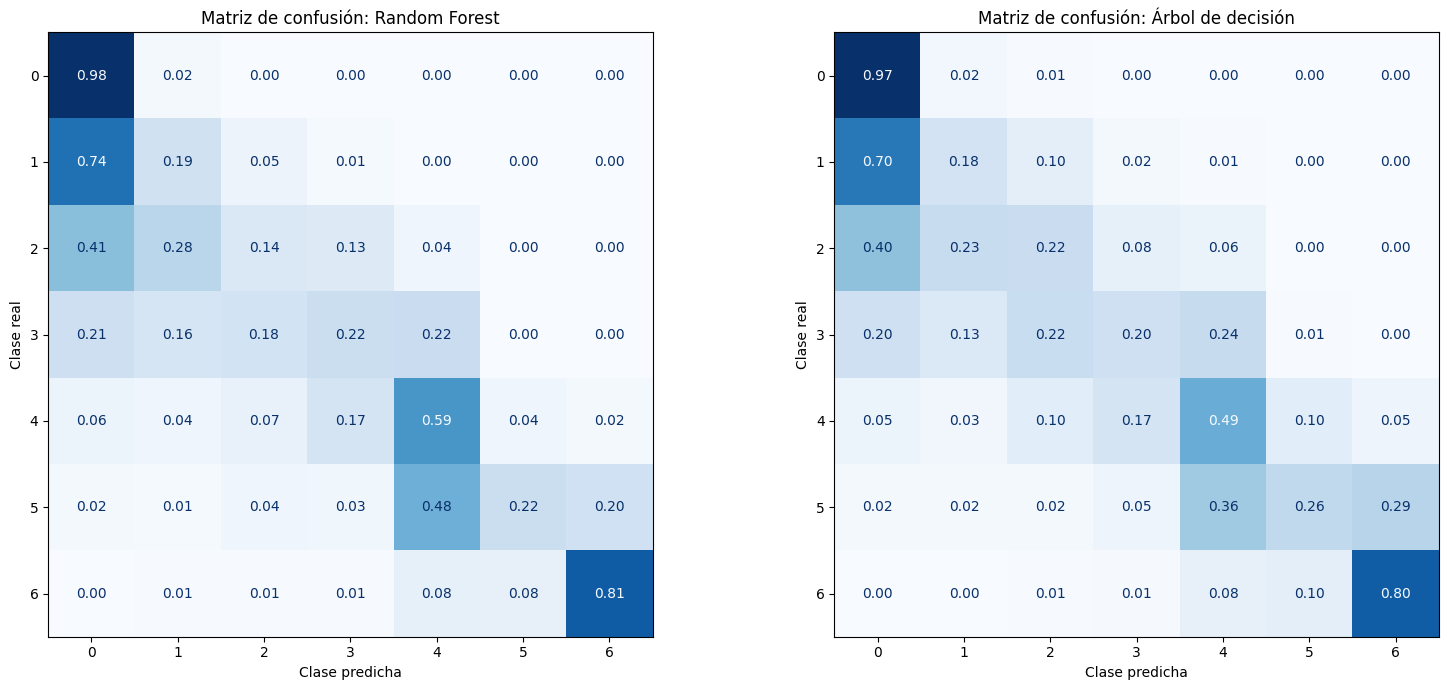

In [ ]:
# Matrices de confusión de los 2 modelos (normalizadas por fila)
# Cada fila es una clase real y muestra qué fracción de esos juegos se predijo en cada clase
# Lo ideal es que la diagonal tenga valores cercanos a 1
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for i in range(2):
    ConfusionMatrixDisplay.from_predictions(y_test_multi, predicciones[i], normalize="true",
                                            values_format=".2f", cmap="Blues", colorbar=False, ax=axes[i])
    axes[i].set_title("Matriz de confusión: " + mejores_2[i])
    axes[i].set_xlabel("Clase predicha")
    axes[i].set_ylabel("Clase real")

plt.tight_layout()
plt.show()


# **AVANCE 3**

# **MODELOS DE REGRESIÓN (predecir `estimated_owners` como número)**

En el avance 2 se clasificaba a los juegos (2 clases y 7 clases). Ahora se predice directamente la cantidad estimada de dueños, o sea un valor numérico. Se usan los mismos pasos del avance 2: mismas filas de train, validación y test, mismos barridos de hiperparámetros con `for`, mismas gráficas y la misma tabla final.

**Modelos** (el equivalente de regresión de cada uno del avance 2):
- Regresión lineal (con `Ridge`, que es regresión lineal con un hiperparámetro `alpha`) en lugar de Gaussian NB, porque Gaussian NB solo existe para clasificación.
- `DecisionTreeRegressor` (árbol de decisión).
- `RandomForestRegressor` (bosque aleatorio).
- `SVR` (SVM para regresión).

**Variable objetivo:** `log10(estimated_owners)`. Los owners van de 10.000 a 150.000.000 y están muy sesgados (la mayoría de juegos tiene pocos), así que se trabaja en escala logarítmica. Así un error de "un orden de magnitud" pesa igual para juegos pequeños y grandes.

**Métricas de regresión:** MAE, RMSE y R² (en escala log10). F1, precisión, recall y especificidad son métricas de clasificación y no se usan aquí; la especificidad se usó en el avance 2.

**Criterio para elegir el mejor modelo:** primero R² (de mayor a menor) y, si empatan, RMSE (de menor a mayor).

In [ ]:
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

## Variable objetivo continua y separación de los datos

In [ ]:
# La variable objetivo continua sale de pdgames (el punto medio de cada rango de owners)
# Los índices de steamdf y pdgames son los mismos, así que se usan las mismas filas de train, validación y test
y_reg = np.log10(pdgames["estimated_owners"])

y_train_reg = y_reg.loc[X_train.index]
y_val_reg = y_reg.loc[X_val.index]
y_test_reg = y_reg.loc[X_test.index]

print("Resumen de log10(estimated_owners) en train:\n")
print(y_train_reg.describe().round(3))

## Funciones de evaluación

`metricas_reg` calcula las métricas a partir de los valores reales y las predicciones. `evaluar_reg` entrena un modelo con train y lo mide en validación (igual que `evaluar` del avance 2).

In [ ]:
def metricas_reg(y_real, y_pred):
    # Métricas de regresión (en escala log10)
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    return {"MAE": mae, "RMSE": rmse, "R2": r2}


def evaluar_reg(modelo, X_tr=None, y_tr=None):
    # Entrena el modelo con train y lo prueba con validación
    # Devuelve (R2, MAE, RMSE)
    # X_tr / y_tr permiten entrenar con menos filas (se usa en SVR, que es lento)
    if X_tr is None:
        X_tr, y_tr = X_train, y_train_reg
    modelo.fit(X_tr, y_tr)
    m = metricas_reg(y_val_reg, modelo.predict(X_val))
    return m["R2"], m["MAE"], m["RMSE"]


def graficar_reg(ax, valores, resultados, titulo, elegido):
    # R2 en el eje izquierdo (más alto = mejor); MAE y RMSE en el derecho (más bajo = mejor)
    resultados = np.array(resultados)
    posiciones = list(range(len(valores)))
    etiquetas = [str(v) for v in valores]

    ax.plot(posiciones, resultados[:, 0], marker="o", linewidth=3, color="red", label="R²")
    ax.set_ylabel("R² (validación)")
    ax.set_xlabel("Valor probado")
    ax.set_xticks(posiciones)
    ax.set_xticklabels(etiquetas)
    ax.set_title(titulo)
    ax.grid(True, alpha=0.3)

    ax2 = ax.twinx()
    ax2.plot(posiciones, resultados[:, 1], marker="s", color="blue", label="MAE")
    ax2.plot(posiciones, resultados[:, 2], marker="^", color="green", label="RMSE")
    ax2.set_ylabel("Error (log10 owners)")

    if str(elegido) in etiquetas:
        ax.axvline(etiquetas.index(str(elegido)), color="gray", linestyle="--", label="Valor elegido")

    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=8, framealpha=0.8)

## Exploración de hiperparámetros

Todas las métricas se miden en validación. En cada gráfica la línea roja gruesa es el R² (eje izquierdo, más alto es mejor), la azul es el MAE y la verde es el RMSE (eje derecho, más bajo es mejor). La línea gris punteada marca el valor elegido (que se define en la celda de "Mejores hiperparámetros", más abajo).

Los valores elegidos son un punto de partida: **hay que revisar las gráficas y cambiarlos si otro valor da mejores resultados**.

In [ ]:
# Hiperparámetros elegidos (revisar con las gráficas y ajustar si hace falta)
reg_alpha = 10

arbol_reg_max_depth = 10
arbol_reg_min_samples_split = 50
arbol_reg_criterion = "squared_error"

bosque_reg_n_estimators = 200
bosque_reg_max_depth = 10
bosque_reg_min_samples_leaf = 2

svr_C = 1
svr_kernel = "rbf"
svr_epsilon = 0.1

# El SVR es muy lento con decenas de miles de filas, así que se explora con una muestra de train
N_SVR = 10000
rng_svr = np.random.RandomState(31)
idx_svr = rng_svr.choice(len(X_train), size=min(N_SVR, len(X_train)), replace=False)
X_train_svr = X_train.iloc[idx_svr]
y_train_svr = y_train_reg.iloc[idx_svr]

### Regresión lineal (Ridge)

In [ ]:
print("\nExplorando regresión lineal\n")

# Regresión lineal simple (sin hiperparámetros) como punto de referencia
lineal = make_pipeline(StandardScaler(), LinearRegression())
print("Regresión lineal simple (R2, MAE, RMSE):", np.round(evaluar_reg(lineal), 3))

# alpha (fuerza de la regularización)
valores_alpha = [0.01, 0.1, 1, 10, 100, 1000]
resultados_alpha = []
for v in valores_alpha:
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=v))
    resultados_alpha.append(evaluar_reg(ridge))

fig, ax = plt.subplots(figsize=(7, 5))
graficar_reg(ax, valores_alpha, resultados_alpha, "Regresión lineal (Ridge): alpha", reg_alpha)
plt.tight_layout()
plt.show()

### Árbol de decisión (regresión)

In [ ]:
print("\nExplorando árboles de decisión (regresión)\n")

# max_depth (lo demás en valores por defecto)
valores_depth_r = [3, 5, 10, 20, None]
resultados_depth_r = []
for v in valores_depth_r:
    arbol = DecisionTreeRegressor(max_depth=v, random_state=31)
    resultados_depth_r.append(evaluar_reg(arbol))

# min_samples_split (con max_depth = 10)
valores_split_r = [2, 10, 50, 200]
resultados_split_r = []
for v in valores_split_r:
    arbol = DecisionTreeRegressor(max_depth=10, min_samples_split=v, random_state=31)
    resultados_split_r.append(evaluar_reg(arbol))

# criterion (con max_depth = 10 y min_samples_split = 50)
# absolute_error es el más lento porque usa la mediana
valores_criterio_r = ["squared_error", "poisson", "absolute_error"]
resultados_criterio_r = []
for v in valores_criterio_r:
    arbol = DecisionTreeRegressor(max_depth=10, min_samples_split=50, criterion=v, random_state=31)
    resultados_criterio_r.append(evaluar_reg(arbol))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
graficar_reg(axes[0], valores_depth_r, resultados_depth_r, "Árbol: max_depth", arbol_reg_max_depth)
graficar_reg(axes[1], valores_split_r, resultados_split_r, "Árbol: min_samples_split", arbol_reg_min_samples_split)
graficar_reg(axes[2], valores_criterio_r, resultados_criterio_r, "Árbol: criterion", arbol_reg_criterion)
plt.suptitle("Exploración de hiperparámetros: árboles de decisión (regresión)")
plt.tight_layout()
plt.show()

### Random Forest (regresión)

In [ ]:
print("\nExplorando Random Forest (regresión)\n")

# n_estimators (lo demás en valores por defecto)
valores_estimators_r = [10, 50, 100, 200]
resultados_estimators_r = []
for v in valores_estimators_r:
    bosque = RandomForestRegressor(n_estimators=v, random_state=31, n_jobs=-1)
    resultados_estimators_r.append(evaluar_reg(bosque))

# max_depth (con n_estimators = 200)
valores_depth_bosque_r = [3, 5, 10, 20, None]
resultados_depth_bosque_r = []
for v in valores_depth_bosque_r:
    bosque = RandomForestRegressor(n_estimators=200, max_depth=v, random_state=31, n_jobs=-1)
    resultados_depth_bosque_r.append(evaluar_reg(bosque))

# min_samples_leaf (con n_estimators = 200 y max_depth = 10)
valores_leaf_r = [2, 10, 50, 200]
resultados_leaf_r = []
for v in valores_leaf_r:
    bosque = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=v, random_state=31, n_jobs=-1)
    resultados_leaf_r.append(evaluar_reg(bosque))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
graficar_reg(axes[0], valores_estimators_r, resultados_estimators_r, "Random Forest: n_estimators", bosque_reg_n_estimators)
graficar_reg(axes[1], valores_depth_bosque_r, resultados_depth_bosque_r, "Random Forest: max_depth", bosque_reg_max_depth)
graficar_reg(axes[2], valores_leaf_r, resultados_leaf_r, "Random Forest: min_samples_leaf", bosque_reg_min_samples_leaf)
plt.suptitle("Exploración de hiperparámetros: Random Forest (regresión)")
plt.tight_layout()
plt.show()

### Support Vector Regression (SVR)

In [ ]:
print("\nExplorando SVR con una muestra de", len(X_train_svr), "filas de train. Puede tardar varios minutos\n")

# C (lo demás en valores por defecto)
valores_C = [0.1, 1, 10]
resultados_C = []
for v in valores_C:
    svr = make_pipeline(StandardScaler(), SVR(C=v))
    resultados_C.append(evaluar_reg(svr, X_train_svr, y_train_svr))
print("Listo el barrido de C")

# kernel (con C = 1)
valores_kernel = ["linear", "rbf", "sigmoid"]
resultados_kernel = []
for v in valores_kernel:
    svr = make_pipeline(StandardScaler(), SVR(C=1, kernel=v))
    resultados_kernel.append(evaluar_reg(svr, X_train_svr, y_train_svr))
print("Listo el barrido de kernel")

# epsilon (con C = 1 y kernel rbf): es el margen dentro del cual no se penaliza el error
valores_epsilon = [0.01, 0.1, 0.5]
resultados_epsilon = []
for v in valores_epsilon:
    svr = make_pipeline(StandardScaler(), SVR(C=1, kernel="rbf", epsilon=v))
    resultados_epsilon.append(evaluar_reg(svr, X_train_svr, y_train_svr))
print("Listo el barrido de epsilon")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
graficar_reg(axes[0], valores_C, resultados_C, "SVR: C", svr_C)
graficar_reg(axes[1], valores_kernel, resultados_kernel, "SVR: kernel", svr_kernel)
graficar_reg(axes[2], valores_epsilon, resultados_epsilon, "SVR: epsilon", svr_epsilon)
plt.suptitle("Exploración de hiperparámetros: SVR")
plt.tight_layout()
plt.show()

## Comparación de los 4 modelos con sus mejores hiperparámetros

Se entrenan los 4 modelos con los hiperparámetros elegidos y se comparan en validación. El orden es primero R² y luego RMSE. También se calcula el R² en train para detectar sobreajuste (si es mucho mayor que el de validación, el modelo memoriza).

In [ ]:
modelos_reg = {
    "Regresión lineal (Ridge)": make_pipeline(StandardScaler(), Ridge(alpha=reg_alpha)),
    "Árbol de decisión": DecisionTreeRegressor(max_depth=arbol_reg_max_depth,
                                               min_samples_split=arbol_reg_min_samples_split,
                                               criterion=arbol_reg_criterion,
                                               random_state=31),
    "Random Forest": RandomForestRegressor(n_estimators=bosque_reg_n_estimators,
                                           max_depth=bosque_reg_max_depth,
                                           min_samples_leaf=bosque_reg_min_samples_leaf,
                                           random_state=31,
                                           n_jobs=-1),
    "SVR": make_pipeline(StandardScaler(), SVR(C=svr_C, kernel=svr_kernel, epsilon=svr_epsilon)),
}

filas_reg = []
for nombre, modelo in modelos_reg.items():
    print("Entrenando:", nombre)
    if nombre == "SVR":
        modelo.fit(X_train_svr, y_train_svr)      # solo la muestra de train, por velocidad
    else:
        modelo.fit(X_train, y_train_reg)

    m = metricas_reg(y_val_reg, modelo.predict(X_val))
    r2_train = r2_score(y_train_reg, modelo.predict(X_train))
    filas_reg.append([nombre, m["MAE"], m["RMSE"], m["R2"], r2_train])

tabla_reg = pd.DataFrame(filas_reg, columns=["Modelo", "MAE", "RMSE", "R2", "R2 train"])
tabla_reg = tabla_reg.round(3)
tabla_reg = tabla_reg.sort_values(by=["R2", "RMSE"], ascending=[False, True]).reset_index(drop=True)

print("\n\nResultados en validación, ordenados de mejor a peor:\n")
print(tabla_reg)

mejores_2_reg = tabla_reg["Modelo"].head(2).tolist()
print("\nEl mejor modelo es:", mejores_2_reg[0])
print("El segundo mejor modelo es:", mejores_2_reg[1])

In [ ]:
# Gráfica de barras con las métricas de cada modelo (validación)
metricas_barras = ["R2", "MAE", "RMSE"]
colores = ["red", "blue", "green"]

ax = tabla_reg.set_index("Modelo")[metricas_barras].plot(kind="bar", figsize=(11, 5), color=colores)
ax.set_title("Comparación de modelos de regresión en validación")
ax.set_ylabel("Valor de la métrica")
ax.set_xlabel("")
ax.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## Evaluación final en test (los 2 mejores modelos)

El conjunto de test se usa solo aquí. Se muestran las métricas, la gráfica de valores reales contra predichos y la distribución de los residuos.

In [ ]:
filas_test = []
predicciones_reg = []

for nombre in mejores_2_reg:
    modelo = clone(modelos_reg[nombre])
    if nombre == "SVR":
        modelo.fit(X_train_svr, y_train_svr)
    else:
        modelo.fit(X_train, y_train_reg)

    y_pred = modelo.predict(X_test)
    predicciones_reg.append(y_pred)

    m = metricas_reg(y_test_reg, y_pred)
    filas_test.append([nombre, m["MAE"], m["RMSE"], m["R2"]])

tabla_test_reg = pd.DataFrame(filas_test, columns=["Modelo", "MAE", "RMSE", "R2"])
tabla_test_reg = tabla_test_reg.round(3)
tabla_test_reg = tabla_test_reg.sort_values(by=["R2", "RMSE"], ascending=[False, True]).reset_index(drop=True)

print("Resultados en test:\n")
print(tabla_test_reg)
print("\nEl mejor modelo en test es:", tabla_test_reg.loc[0, "Modelo"])

In [ ]:
# Valores reales contra predichos y distribución de residuos (test)
# En la gráfica de la izquierda lo ideal es que los puntos queden sobre la línea roja
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for i, nombre in enumerate(mejores_2_reg):
    y_pred = predicciones_reg[i]

    axes[0, i].scatter(y_test_reg, y_pred, alpha=0.15, s=8, color="teal")
    lim = [min(y_test_reg.min(), y_pred.min()), max(y_test_reg.max(), y_pred.max())]
    axes[0, i].plot(lim, lim, color="red", linestyle="--", label="Predicción perfecta")
    axes[0, i].set_title("Real vs predicho: " + nombre)
    axes[0, i].set_xlabel("log10(owners) real")
    axes[0, i].set_ylabel("log10(owners) predicho")
    axes[0, i].legend(fontsize=8)
    axes[0, i].grid(alpha=0.3)

    residuos = y_test_reg.values - y_pred
    sns.histplot(residuos, bins=50, kde=True, color="steelblue", ax=axes[1, i])
    axes[1, i].axvline(0, color="red", linestyle="--")
    axes[1, i].set_title("Residuos (real - predicho): " + nombre)
    axes[1, i].set_xlabel("Error en log10(owners)")
    axes[1, i].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()